# **Project Name**    - **Gender Classification of Travel Platform Users**


##### **Project Type**    - Classification
##### **Contribution**    - Individual
##### **Team Member 1 -**

# **Project Summary -**

This notebook is one part of my travel MLOps capstone. The project uses three related datasets from a travel platform: users, flights and hotels. In this notebook I work on one problem, which is predicting the gender of a user.

When I explored users.csv I found 1340 users with five columns and no missing or duplicated rows. The gender column has three values: male (452), female (448) and none (440). The 'none' group is almost exactly one third of the users and I don't think it is a real category. 66.8% of the 'none' users share their first name with a labeled user, for example Trina, Jack and Debbie, so 'none' looks more like "gender was not recorded". Because of this I treated those 440 users as unlabeled data, trained the model only on male vs female, and at the end used the trained model to fill in their missing gender with a confidence score.

For the EDA I made 15 charts following the UBM rule. The main thing the charts showed is that age, company and travel behaviour are almost the same for men and women. The average age is 43.2 for women and 42.7 for men, the gender split inside each company stays close to one third each, and the number of flights, ticket price, flight class and hotel spend hardly change between genders. The only clear pattern was in the first name. 167 of the 169 labeled first names ending in "a" are female, while names ending in "d", "m" or "k" are almost all male. The correlation heatmap tells the same story: ends_with_vowel has a correlation of 0.53 with the target, while every behaviour column is below 0.06.

I tested three hypotheses. There was no significant age difference between men and women (Welch t-test, p = 0.58). Gender was independent of company (chi-square, p = 0.79). The ending of the first name was strongly related to gender (chi-square, p close to zero, Cramer's V = 0.53).

For feature engineering I filled the 115 nulls that came from users without bookings with zero and checked the outliers, which I kept because they are valid values. Then I cleaned the names with the text preprocessing steps: lower casing, removing punctuation and digits, trimming spaces, tokenizing to get the first name, and unicode normalization. After that I compared three feature groups with 5-fold cross validation. Age, company and behaviour gave 47% to 49% accuracy, which is no better than a coin flip. Hand made name suffix features gave 85.8%, and TF-IDF character n-grams of the first name gave 88.4%. So the final model only uses the first name.

I trained Logistic Regression, Multinomial Naive Bayes and Random Forest, and tuned each one with GridSearchCV or RandomizedSearchCV. The tuned Logistic Regression had the best cross validation accuracy (90.7%). On the test set it got 88.3% accuracy, 0.916 precision, 0.844 recall and 0.958 ROC-AUC. I also checked how the models do on first names they have never seen before using GroupKFold, and Logistic Regression was again the best with 75.6%. I picked it as the final model because it was the most stable across these checks and it gives probabilities. It is also easy to explain, and the saved file is only 70 KB.

Finally I saved the model with joblib, loaded it back and predicted on new names and on the 440 'none' users. 78.4% of those predictions have a confidence of 0.8 or more, so the platform can fill most of the missing values and leave the uncertain ones as unknown.

# **GitHub Link -**

https://github.com/Tahascommit/travel-mlops-capstone

The repo has all three notebooks of the project (flight price regression, gender classification and hotel recommendation), the training scripts and the deployment files.

# **Problem Statement**


The travel platform keeps a profile for every user with their company, name, gender and age. For 440 of the 1340 users (about one third) the gender field is stored as 'none', which means it was never filled in. Gender is one of the basic fields the business uses for customer reports, segmentation and personalised offers, so having a third of it missing makes all of those less reliable.

The task is to build a classification model that predicts whether a user is male or female from the information we have for every user (name, age, company and their flight and hotel history). The model then has to be saved so it can be used outside the notebook to fill in the missing values.

Business objective: fill in the missing gender values with a model whose accuracy we know, and return a confidence score with each prediction so that only confident predictions are used. The predictions are meant for aggregate things like reports and segment level marketing, not for making decisions about one specific person.

# **General Guidelines** : -  

1.   Well-structured, formatted, and commented code is required. 
2.   Exception Handling, Production Grade Code & Deployment Ready Code will be a plus. Those students will be awarded some additional credits. 
     
     The additional credits will have advantages over other students during Star Student selection.
       
             [ Note: - Deployment Ready Code is defined as, the whole .ipynb notebook should be executable in one go
                       without a single error logged. ]

3.   Each and every logic should have proper comments.
4. You may add as many number of charts you want. Make Sure for each and every chart the following format should be answered.
        

```
# Chart visualization code
```
            

*   Why did you pick the specific chart?
*   What is/are the insight(s) found from the chart?
* Will the gained insights help creating a positive business impact? 
Are there any insights that lead to negative growth? Justify with specific reason.

5. You have to create at least 15 logical & meaningful charts having important insights.


[ Hints : - Do the Vizualization in  a structured way while following "UBM" Rule. 

U - Univariate Analysis,

B - Bivariate Analysis (Numerical - Categorical, Numerical - Numerical, Categorical - Categorical)

M - Multivariate Analysis
 ]





6. You may add more ml algorithms for model creation. Make sure for each and every algorithm, the following format should be answered.


*   Explain the ML Model used and it's performance using Evaluation metric Score Chart.


*   Cross- Validation & Hyperparameter Tuning

*   Have you seen any improvement? Note down the improvement with updates Evaluation metric Score Chart.

*   Explain each evaluation metric's indication towards business and the business impact pf the ML model used.




















# ***Let's Begin !***

## ***1. Know Your Data***

### Import Libraries

In [1]:
# Import Libraries
import os
import re
import unicodedata
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from sklearn.model_selection import (train_test_split, StratifiedKFold, GroupKFold,
                                     cross_val_score, GridSearchCV, RandomizedSearchCV)
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.feature_selection import chi2
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.decomposition import TruncatedSVD
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, confusion_matrix, classification_report)
import joblib

# shap is used at the end for model explainability (it is preinstalled on colab, install it if missing)
try:
    import shap
except ImportError:
    import subprocess, sys
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "shap"])
    import shap

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)
RANDOM_STATE = 42

### Dataset Loading

In [2]:
# Load Dataset
# inside the repo we read the local csv files, on colab the same files are pulled from github
DATA_PATH = "../data/raw/" if os.path.exists("../data/raw/users.csv") else "https://raw.githubusercontent.com/Tahascommit/travel-mlops-capstone/main/data/raw/"

try:
    users = pd.read_csv(DATA_PATH + "users.csv")
    flights = pd.read_csv(DATA_PATH + "flights.csv")
    hotels = pd.read_csv(DATA_PATH + "hotels.csv")
except Exception as e:
    raise RuntimeError(f"Could not load the data from {DATA_PATH}: {e}")

print("Data loaded from:", DATA_PATH)

Data loaded from: ../data/raw/


### Dataset First View

In [3]:
# Dataset First Look
# users is the main table for this problem, flights and hotels are only used to build behaviour features
users.head(10)

,code,company,name,gender,age
0,0,4You,Roy Braun,male,21
1,1,4You,Joseph Holsten,male,37
2,2,4You,Wilma Mcinnis,female,48
3,3,4You,Paula Daniel,female,23
4,4,4You,Patricia Carson,female,44
5,5,4You,Trina Thomas,none,47
6,6,4You,Jesse Decelle,male,46
7,7,4You,Gregoria Gil,female,21
8,8,4You,Jack Sabo,none,41
9,9,4You,Debbie Helms,none,35


In [4]:
# first rows of the two booking tables, joined to users through userCode
display(flights.head(3))
display(hotels.head(3))

,travelCode,userCode,from,to,flightType,price,time,distance,agency,date
0,0,0,Recife (PE),Florianopolis (SC),firstClass,1434.38,1.76,676.53,FlyingDrops,09/26/2019
1,0,0,Florianopolis (SC),Recife (PE),firstClass,1292.29,1.76,676.53,FlyingDrops,09/30/2019
2,1,0,Brasilia (DF),Florianopolis (SC),firstClass,1487.52,1.66,637.56,CloudFy,10/03/2019


,travelCode,userCode,name,place,days,price,total,date
0,0,0,Hotel A,Florianopolis (SC),4,313.02,1252.08,09/26/2019
1,2,0,Hotel K,Salvador (BH),2,263.41,526.82,10/10/2019
2,7,0,Hotel K,Salvador (BH),3,263.41,790.23,11/14/2019


### Dataset Rows & Columns count

In [5]:
# Dataset Rows & Columns count
for name, data in [("users", users), ("flights", flights), ("hotels", hotels)]:
    print(f"{name:<8} rows: {data.shape[0]:>7}   columns: {data.shape[1]}")

users    rows:    1340   columns: 5
flights  rows:  271888   columns: 10
hotels   rows:   40552   columns: 8


### Dataset Information

In [6]:
# Dataset Info
users.info()

<class 'pandas.DataFrame'>
RangeIndex: 1340 entries, 0 to 1339
Data columns (total 5 columns):
 #   Column   Non-Null Count  Dtype
---  ------   --------------  -----
 0   code     1340 non-null   int64
 1   company  1340 non-null   str  
 2   name     1340 non-null   str  
 3   gender   1340 non-null   str  
 4   age      1340 non-null   int64
dtypes: int64(2), str(3)
memory usage: 88.3 KB


#### Duplicate Values

In [7]:
# Dataset Duplicate Value Count
print("Fully duplicated rows in users :", users.duplicated().sum())
print("Duplicated user codes          :", users["code"].duplicated().sum())

# two full names repeat, but they have different codes and ages so they are different people
dup_names = users[users["name"].duplicated(keep=False)].sort_values("name")
print("Users sharing the same full name:", len(dup_names))
dup_names

Fully duplicated rows in users : 0
Duplicated user codes          : 0
Users sharing the same full name: 4


,code,company,name,gender,age
316,316,4You,Charlotte Johnson,female,64
496,496,Monsters CYA,Charlotte Johnson,none,51
309,309,4You,David Robinson,male,33
946,946,Acme Factory,David Robinson,none,30


#### Missing Values/Null Values

In [8]:
# Missing Values/Null Values Count
print(users.isnull().sum())

code       0
company    0
name       0
gender     0
age        0
dtype: int64


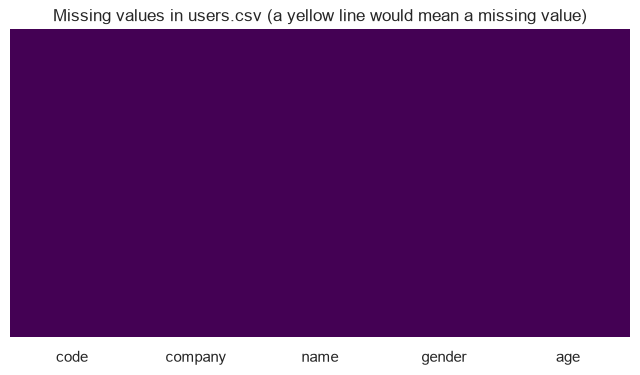

In [9]:
# Visualizing the missing values
plt.figure(figsize=(8, 4))
sns.heatmap(users.isnull(), cbar=False, yticklabels=False, cmap="viridis")
plt.title("Missing values in users.csv (a yellow line would mean a missing value)")
plt.show()

### What did you know about your dataset?

- The users dataset has 1340 rows and 5 columns: code, company, name, gender and age. There are no missing values and no duplicate rows, and every user code is unique.
- Two full names repeat (Charlotte Johnson and David Robinson), but they belong to different people with different codes, companies and ages, so they are not duplicates.
- The gender column is split almost evenly into male (452), female (448) and none (440).
- Every name has exactly two words, first name and last name, so it is easy to split.
- Flights (271,888 rows) and hotels (40,552 rows) connect to users through userCode. I use them only to build behaviour features for each user, so I can check whether travel habits say anything about gender.

## ***2. Understanding Your Variables***

In [10]:
# Dataset Columns
users.columns.tolist()

['code', 'company', 'name', 'gender', 'age']

In [11]:
# Dataset Describe
users.describe(include="all")

,code,company,name,gender,age
count,1340.000000,1340,1340,1340,1340.000000
unique,NaN,5,1338,3,NaN
top,NaN,4You,David Robinson,male,NaN
freq,NaN,453,2,452,NaN
mean,669.500000,NaN,NaN,NaN,42.742537
std,386.968991,NaN,NaN,NaN,12.869779
min,0.000000,NaN,NaN,NaN,21.000000
25%,334.750000,NaN,NaN,NaN,32.000000
50%,669.500000,NaN,NaN,NaN,42.000000
75%,1004.250000,NaN,NaN,NaN,54.000000


### Variables Description 

**Original columns (users.csv)**

* **code :** unique id of the user, also used as userCode in flights and hotels
* **company :** the company the user belongs to (5 companies)
* **name :** full name of the user, always "First Last"
* **gender :** male, female or none (none = not recorded), this is the target
* **age :** age of the user in years, from 21 to 65

**Columns I created in data wrangling**

* **first_name / last_name :** the two parts of the name
* **name_length :** number of letters in the first name
* **last_letter :** last letter of the first name
* **ends_with_vowel :** 1 if the first name ends with a, e, i, o or u
* **n_flights, avg_flight_price, total_flight_spend, first_class_share, avg_flight_distance :** flight behaviour of the user
* **n_hotel_stays, avg_hotel_days, total_hotel_spend :** hotel behaviour of the user

### Check Unique Values for each variable.

In [12]:
# Check Unique Values for each variable.
for col in users.columns:
    print(f"No. of unique values in {col:<8} : {users[col].nunique()}")

print("\nGender values :", users["gender"].unique().tolist())
print("Companies     :", users["company"].unique().tolist())

No. of unique values in code     : 1340
No. of unique values in company  : 5
No. of unique values in name     : 1338
No. of unique values in gender   : 3
No. of unique values in age      : 45

Gender values : ['male', 'female', 'none']
Companies     : ['4You', 'Monsters CYA', 'Wonka Company', 'Acme Factory', 'Umbrella LTDA']


## 3. ***Data Wrangling***

### Data Wrangling Code

In [13]:
# Write your code to make your dataset analysis ready.
df = users.copy()

# every name in this data is "First Last", so splitting on the space gives first and last name
print("Words per name:", df["name"].str.split().str.len().value_counts().to_dict())
df["first_name"] = df["name"].str.split().str[0]
df["last_name"] = df["name"].str.split().str[-1]

# simple name based columns, used in the charts
VOWELS = set("aeiou")
df["name_length"] = df["first_name"].str.len()
df["last_letter"] = df["first_name"].str[-1].str.lower()
df["ends_with_vowel"] = df["last_letter"].isin(VOWELS).astype(int)

# travel behaviour per user from the flights and hotels tables
flight_agg = flights.groupby("userCode").agg(
    n_flights=("price", "size"),
    avg_flight_price=("price", "mean"),
    total_flight_spend=("price", "sum"),
    first_class_share=("flightType", lambda s: (s == "firstClass").mean()),
    avg_flight_distance=("distance", "mean"),
)
hotel_agg = hotels.groupby("userCode").agg(
    n_hotel_stays=("total", "size"),
    avg_hotel_days=("days", "mean"),
    total_hotel_spend=("total", "sum"),
)
df = df.merge(flight_agg, left_on="code", right_index=True, how="left")
df = df.merge(hotel_agg, left_on="code", right_index=True, how="left")
behaviour_cols = list(flight_agg.columns) + list(hotel_agg.columns)
print("Users with no flight booking:", df["n_flights"].isnull().sum())
print("Users with no hotel booking :", df["n_hotel_stays"].isnull().sum())

# 'none' does not look like a real gender here, it is the users whose gender was not recorded
labeled = df[df["gender"] != "none"].reset_index(drop=True)
unlabeled = df[df["gender"] == "none"].reset_index(drop=True)
print("\nLabeled users (male/female):", len(labeled), "| unlabeled ('none'):", len(unlabeled))

# first names that appear with both genders, the model can never get all of these right
fn_gender = labeled.groupby(labeled["first_name"].str.lower())["gender"].nunique()
ambiguous = sorted(fn_gender[fn_gender > 1].index)
print("Unique first names among labeled users:", labeled["first_name"].str.lower().nunique())
print("First names used by both genders:", ambiguous)

seen = unlabeled["first_name"].str.lower().isin(labeled["first_name"].str.lower()).mean()
print(f"'none' users whose first name also appears in the labeled data: {seen:.1%}")

Words per name: {2: 1340}
Users with no flight booking: 5
Users with no hotel booking : 30

Labeled users (male/female): 900 | unlabeled ('none'): 440
Unique first names among labeled users: 484
First names used by both genders: ['jame', 'jean', 'kim', 'leslie', 'robin', 'shawn']
'none' users whose first name also appears in the labeled data: 66.8%


In [14]:
# same first name, different label: these 'none' users have names that are clearly male or female elsewhere
check = unlabeled[unlabeled["first_name"].isin(labeled["first_name"])][["name", "gender"]].head(8).copy()
check["gender_of_same_first_name_in_labeled"] = check["name"].str.split().str[0].map(
    labeled.groupby("first_name")["gender"].agg(lambda s: s.mode()[0]))
check

,name,gender,gender_of_same_first_name_in_labeled
0,Trina Thomas,none,female
1,Jack Sabo,none,male
2,Debbie Helms,none,female
3,Irene Tucker,none,female
4,Victor Tribbett,none,male
5,Tanya Orourke,none,female
6,Christopher Elliott,none,male
7,Helen Selby,none,female


### What all manipulations have you done and insights you found?

What I did:

1. Split the full name into first name and last name. All 1340 names have exactly two words, so this was easy.
2. Made a few simple name columns for the charts: length of the first name, its last letter, and whether it ends with a vowel.
3. Grouped the flights and hotels tables by userCode to get each user's travel behaviour (number of flights, average ticket price, total spend, share of first class flights, average distance, number of hotel stays, average stay length and total hotel spend), then left joined it to the users table. 5 users have no flights and 30 users have no hotel stays, so they get nulls, which I deal with in the missing value section.
4. Separated the 900 labeled users (male/female) from the 440 'none' users.

Insights:

- Only 6 first names are used by both genders among the labeled users (jame, jean, kim, leslie, robin and shawn). No model can get all of these right, but it is a small number.
- 66.8% of the 'none' users have a first name that also appears in the labeled data, and those names are clearly male or female there (Trina, Debbie and Helen are female, Jack, Victor and Christopher are male). This convinced me that 'none' means "not recorded" and is not a third gender category, so I treat these users as unlabeled data to predict, not as a class to train on.

## ***4. Data Vizualization, Storytelling & Experimenting with charts : Understand the relationships between variables***

#### Chart - 1

gender
male      452
female    448
none      440
Name: count, dtype: int64


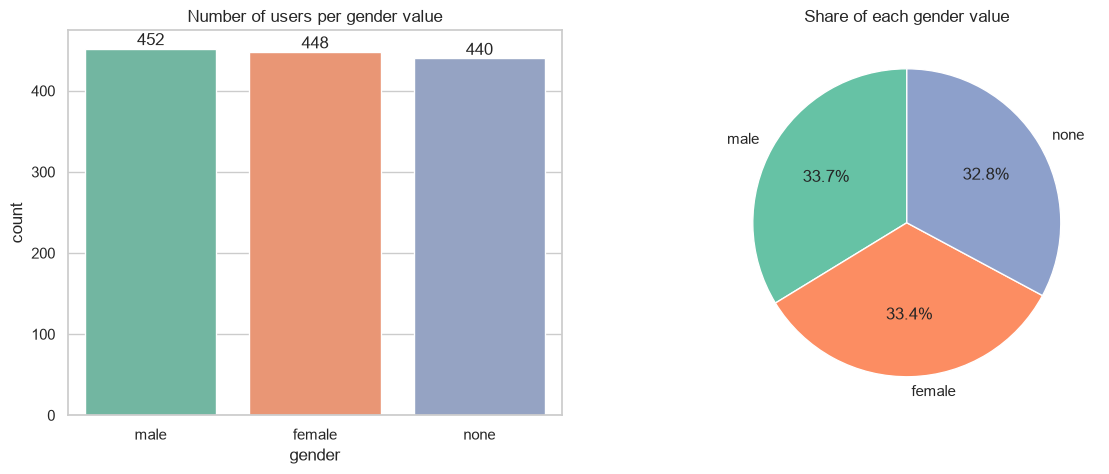

In [15]:
# Chart - 1 visualization code
# Univariate: how the gender column is distributed (all users)
counts = df["gender"].value_counts()
print(counts)

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
sns.countplot(data=df, x="gender", order=counts.index, palette="Set2", ax=ax[0])
for container in ax[0].containers:
    ax[0].bar_label(container)
ax[0].set_title("Number of users per gender value")
ax[1].pie(counts, labels=counts.index, autopct="%1.1f%%", startangle=90, colors=sns.color_palette("Set2"))
ax[1].set_title("Share of each gender value")
plt.show()

##### 1. Why did you pick the specific chart?

I used a count plot together with a pie chart. The count plot shows the exact number of users in each gender value and the pie chart shows each value as a share of the whole, which is the first thing I need to know about the target.

##### 2. What is/are the insight(s) found from the chart?

The three values are almost equal: male 452 (33.7%), female 448 (33.4%) and none 440 (32.8%). Among the labeled users, male and female are basically 50/50, so I don't have a class imbalance problem. On the other hand, a full third of the users have no gender recorded.

##### 3. Will the gained insights help creating a positive business impact? 
Are there any insights that lead to negative growth? Justify with specific reason.

Yes. Since a third of the users have no gender, any report or campaign split by gender is currently missing a third of the customers, and a model that fills these in has a clear use. The balanced classes also mean accuracy will be a fair metric. The negative side is the data quality: 440 profiles missing a basic field suggests the sign up flow doesn't require it, and the business should fix that at the source as well.

#### Chart - 2

count    1340.00
mean       42.74
std        12.87
min        21.00
25%        32.00
50%        42.00
75%        54.00
max        65.00
Name: age, dtype: float64


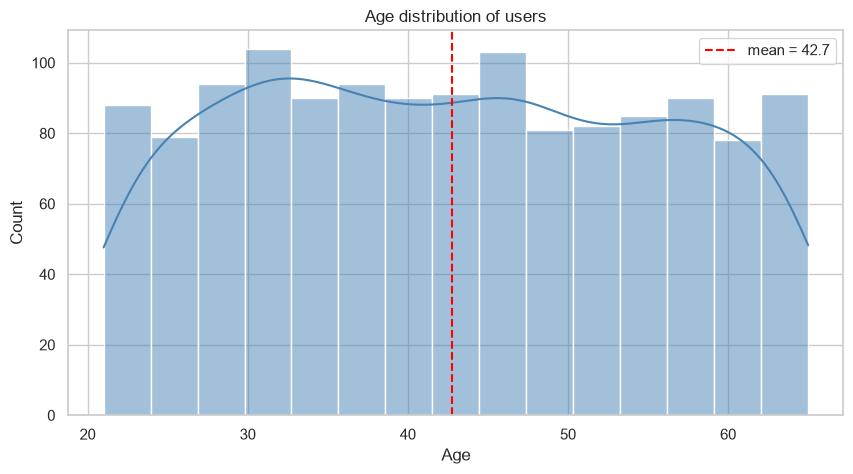

In [16]:
# Chart - 2 visualization code
# Univariate: age of the users
print(df["age"].describe().round(2))

plt.figure(figsize=(10, 5))
sns.histplot(df["age"], bins=15, kde=True, color="steelblue")
plt.axvline(df["age"].mean(), color="red", linestyle="--", label=f"mean = {df['age'].mean():.1f}")
plt.title("Age distribution of users")
plt.xlabel("Age")
plt.legend()
plt.show()

##### 1. Why did you pick the specific chart?

A histogram with a KDE line is the standard way to see the distribution of one numeric column. It shows the range, where most values are, and whether the data is skewed.

##### 2. What is/are the insight(s) found from the chart?

Ages go from 21 to 65 with a mean of 42.7 and a median of 42. The distribution is fairly flat across the whole range with no strong peak, so the users are spread evenly over working ages. There are no extreme or impossible values.

##### 3. Will the gained insights help creating a positive business impact? 
Are there any insights that lead to negative growth? Justify with specific reason.

It helps a bit. The customers are working age adults spread over all age groups, which fits business travel (users belong to companies). Offers can't target just one age band because no group dominates. I didn't see anything here that points to negative growth, although it is worth noting there are no users under 21 or over 65 at all.

#### Chart - 3

company
4You             453
Acme Factory     261
Wonka Company    237
Monsters CYA     195
Umbrella LTDA    194
Name: count, dtype: int64


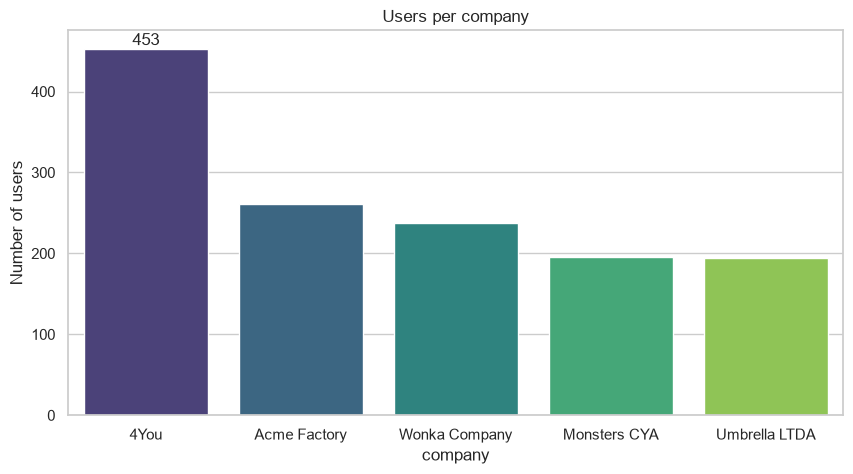

In [17]:
# Chart - 3 visualization code
# Univariate: how many users belong to each company
company_counts = df["company"].value_counts()
print(company_counts)

plt.figure(figsize=(10, 5))
ax = sns.barplot(x=company_counts.index, y=company_counts.values, palette="viridis")
ax.bar_label(ax.containers[0])
plt.title("Users per company")
plt.ylabel("Number of users")
plt.show()

##### 1. Why did you pick the specific chart?

A bar chart is the simplest way to compare counts across categories, and the labels on top give the exact numbers.

##### 2. What is/are the insight(s) found from the chart?

4You is by far the largest company with 453 users, then Acme Factory (261), Wonka Company (237), Monsters CYA (195) and Umbrella LTDA (194). 4You alone has about a third of all users.

##### 3. Will the gained insights help creating a positive business impact? 
Are there any insights that lead to negative growth? Justify with specific reason.

Yes. The platform depends a lot on one client: if 4You left, about a third of the users would go with it. That is a risk to be aware of, and it also means the smaller companies have room to grow. For the gender model this matters because company would only help if the gender mix differs by company, which I check in chart 7.

#### Chart - 4

name_length
2       3
3      38
4     216
5     356
6     306
7     283
8      85
9      38
10      4
11     11
Name: count, dtype: int64


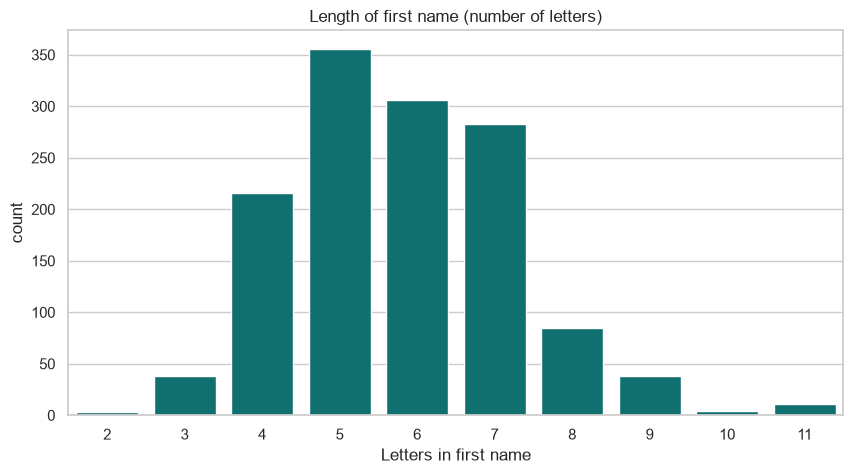

In [18]:
# Chart - 4 visualization code
# Univariate: length of the first name
print(df["name_length"].value_counts().sort_index())

plt.figure(figsize=(10, 5))
sns.countplot(x=df["name_length"], color="teal")
plt.title("Length of first name (number of letters)")
plt.xlabel("Letters in first name")
plt.show()

##### 1. Why did you pick the specific chart?

A count plot shows how often each name length appears. Name length is a small feature I made myself, and I wanted to see its range before comparing it across genders.

##### 2. What is/are the insight(s) found from the chart?

Most first names have 4 to 7 letters. 5 letters is the most common (356 users), followed by 6 (306) and 7 (283). The shortest names have 2 letters (3 users, e.g. "Ma") and the longest have 11 (11 users, e.g. "Christopher").

##### 3. Will the gained insights help creating a positive business impact? 
Are there any insights that lead to negative growth? Justify with specific reason.

On its own this chart doesn't lead to a business action. It is useful for the model: names are short, so a word level approach would have only one token per user, which is why I later use character n-grams instead of whole words. No negative insight here.

#### Chart - 5

first_name
Robert         30
John           24
David          22
William        20
Mary           17
James          17
Linda          12
Christopher    11
Helen          11
Sandra         10
Charles        10
Richard        10
Michael        10
Gary           10
Lisa            9
Name: count, dtype: int64


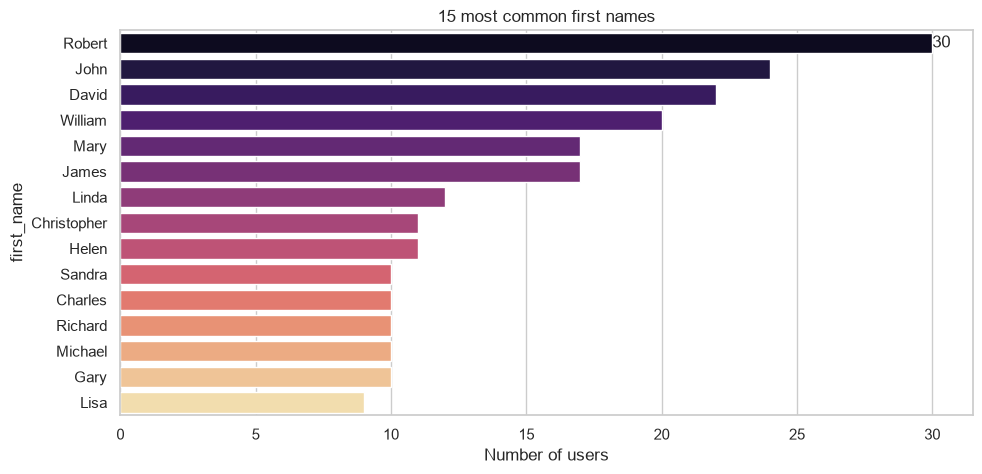

In [19]:
# Chart - 5 visualization code
# Univariate: most common first names
top_names = df["first_name"].value_counts().head(15)
print(top_names)

plt.figure(figsize=(11, 5))
ax = sns.barplot(x=top_names.values, y=top_names.index, palette="magma")
ax.bar_label(ax.containers[0])
plt.title("15 most common first names")
plt.xlabel("Number of users")
plt.show()

##### 1. Why did you pick the specific chart?

A horizontal bar chart is easy to read when the categories are names, and sorting it shows the most common first names first.

##### 2. What is/are the insight(s) found from the chart?

Robert (30), John (24), David (22) and William (20) are the most common first names. Most of the top 15 are typical English names. Some are clearly male (Robert, John, David) and some clearly female (Mary, Linda, Helen, Sandra, Lisa). This tells me the same first name often appears many times, so the model will see many of the test names during training.

##### 3. Will the gained insights help creating a positive business impact? 
Are there any insights that lead to negative growth? Justify with specific reason.

Yes, indirectly. Common names have a known gender, so the model should be very confident on them, and since these names cover many users, a big part of the 'none' users can be filled in correctly. The flip side is that the model could look better than it really is because it has seen the same names before. I check this later by testing on names the model has never seen.

#### Chart - 6

        count   mean    std   min   25%   50%    75%   max
gender                                                    
female  448.0  43.18  13.03  21.0  32.0  44.0  54.25  65.0
male    452.0  42.70  12.89  21.0  32.0  42.5  54.00  65.0
none    440.0  42.34  12.70  21.0  32.0  41.0  53.00  65.0


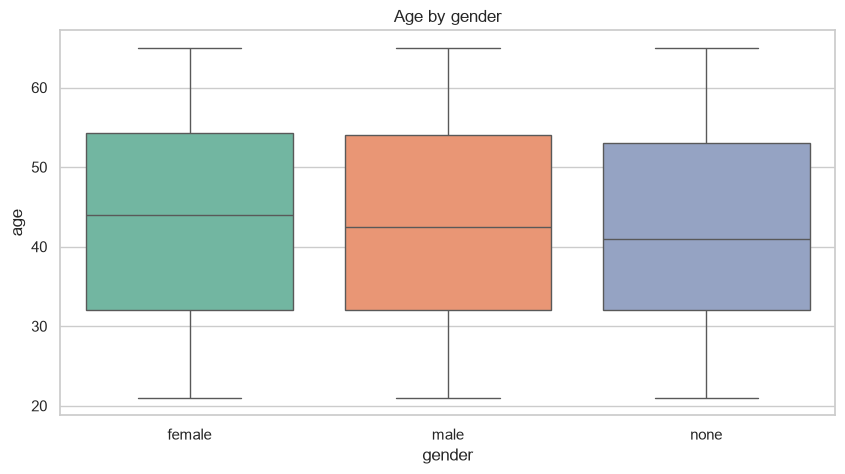

In [20]:
# Chart - 6 visualization code
# Bivariate (numerical - categorical): age by gender
print(df.groupby("gender")["age"].describe().round(2))

plt.figure(figsize=(10, 5))
sns.boxplot(data=df, x="gender", y="age", palette="Set2", order=["female", "male", "none"])
plt.title("Age by gender")
plt.show()

##### 1. Why did you pick the specific chart?

A box plot compares the median, spread and outliers of a numeric column across groups, which is what I need to compare age between the three gender values.

##### 2. What is/are the insight(s) found from the chart?

The three boxes are almost identical. The mean age is 43.2 for female, 42.7 for male and 42.3 for none, and all three go from 21 to 65. The medians are 44, 42.5 and 41. Age does not separate the genders.

##### 3. Will the gained insights help creating a positive business impact? 
Are there any insights that lead to negative growth? Justify with specific reason.

The insight is mostly negative for modelling: age will not help predict gender, so I should not expect anything from it. For the business it shows that men and women on the platform have the same age profile, so age based offers don't need to be different by gender. Also the 'none' group has the same age profile as the others, which again suggests it is just missing data.

#### Chart - 7

gender         female  male  none
company                          
4You             33.3  30.5  36.2
Acme Factory     32.6  35.6  31.8
Monsters CYA     32.8  31.3  35.9
Umbrella LTDA    35.6  36.1  28.4
Wonka Company    33.3  38.0  28.7


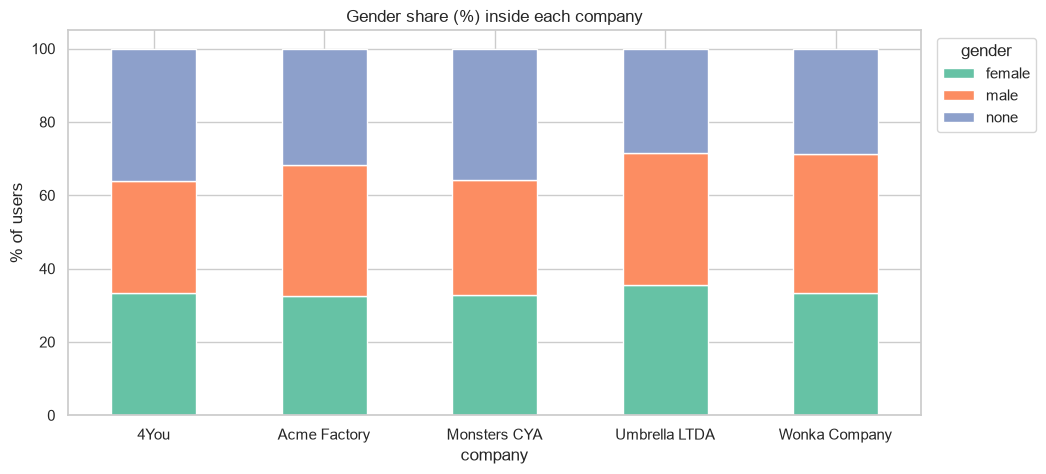

In [21]:
# Chart - 7 visualization code
# Bivariate (categorical - categorical): gender mix inside each company
company_gender = pd.crosstab(df["company"], df["gender"], normalize="index") * 100
print(company_gender.round(1))

company_gender.plot(kind="bar", stacked=True, figsize=(11, 5), color=sns.color_palette("Set2"))
plt.title("Gender share (%) inside each company")
plt.ylabel("% of users")
plt.xticks(rotation=0)
plt.legend(title="gender", bbox_to_anchor=(1.01, 1))
plt.show()

##### 1. Why did you pick the specific chart?

A 100% stacked bar chart shows the share of each gender inside every company, so companies of different sizes can be compared directly.

##### 2. What is/are the insight(s) found from the chart?

Every company has roughly one third of each gender value. Female share goes from 32.6% to 35.6%, and male share from 30.5% (4You) to 38.0% (Wonka Company). The 'none' share is a bit higher in 4You (36.2%) and Monsters CYA (35.9%) than in Umbrella LTDA (28.4%), so some companies may have been worse at filling in the profile.

##### 3. Will the gained insights help creating a positive business impact? 
Are there any insights that lead to negative growth? Justify with specific reason.

It shows that company is not a useful feature for gender. A useful business point is that the missing gender rate differs by company (28% to 36%), so data collection could be improved with the companies that have the most missing profiles. Nothing here points to negative growth.

#### Chart - 8

gender       female  male  total  female_%
last_letter                               
a               167     2    169      98.8
n                50    86    136      36.8
e                97    34    131      74.0
y                62    62    124      50.0
d                 3    50     53       5.7
l                16    32     48      33.3
s                15    33     48      31.2
t                 8    40     48      16.7
r                 7    24     31      22.6
h                12    18     30      40.0
m                 1    24     25       4.0
k                 0    12     12       0.0


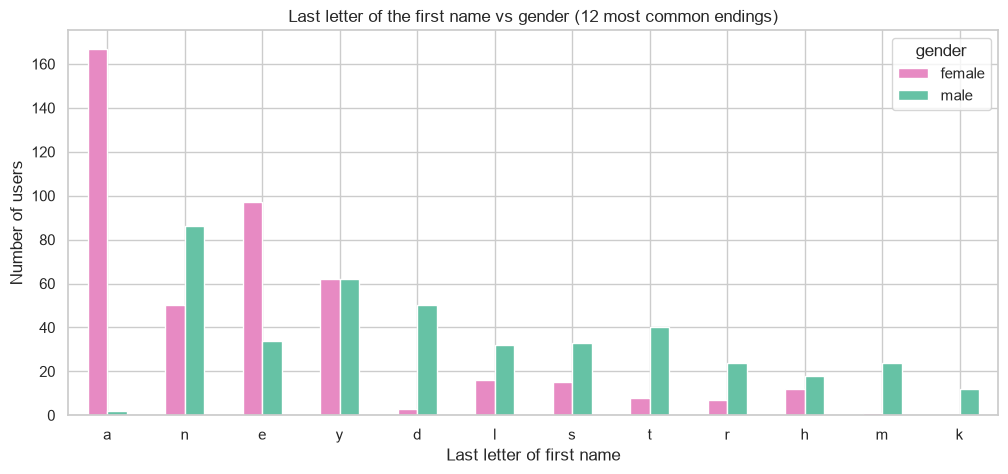

In [22]:
# Chart - 8 visualization code
# Bivariate (categorical - categorical): last letter of the first name vs gender (labeled users only)
letter_gender = pd.crosstab(labeled["last_letter"], labeled["gender"])
letter_gender["total"] = letter_gender.sum(axis=1)
top_letters = letter_gender.sort_values("total", ascending=False).head(12)
top_letters["female_%"] = (top_letters["female"] / top_letters["total"] * 100).round(1)
print(top_letters)

top_letters[["female", "male"]].plot(kind="bar", figsize=(12, 5), color=["#e78ac3", "#66c2a5"])
plt.title("Last letter of the first name vs gender (12 most common endings)")
plt.xlabel("Last letter of first name")
plt.ylabel("Number of users")
plt.xticks(rotation=0)
plt.show()

##### 1. Why did you pick the specific chart?

A grouped bar chart lets me compare female and male counts for each name ending side by side. I only show the 12 most common last letters so the chart stays readable.

##### 2. What is/are the insight(s) found from the chart?

This is the strongest pattern in the whole dataset. Of the 169 labeled first names ending in "a", 167 are female (98.8%). Names ending in "e" are 74% female. On the other side, names ending in "d" (5.7% female), "m" (4.0%) and "k" (0%) are almost all male, and "t" and "r" are mostly male too. Names ending in "y" are exactly 50/50, so for those the ending alone is not enough.

##### 3. Will the gained insights help creating a positive business impact? 
Are there any insights that lead to negative growth? Justify with specific reason.

Yes. It shows that the first name has real signal, and that the model should look at parts of the name (especially the ending) and not just the whole name. That way it can also handle names it has never seen, like a new "Fernanda" or "Ricardo". The negative part is endings like "y" and "n" that are mixed, so the model will be less sure about those names, which is why I keep a confidence score with every prediction.

#### Chart - 9

        count  mean   std  min  25%  50%  75%   max
gender                                             
female  448.0  5.89  1.49  2.0  5.0  6.0  7.0  10.0
male    452.0  5.70  1.35  3.0  5.0  6.0  7.0  11.0


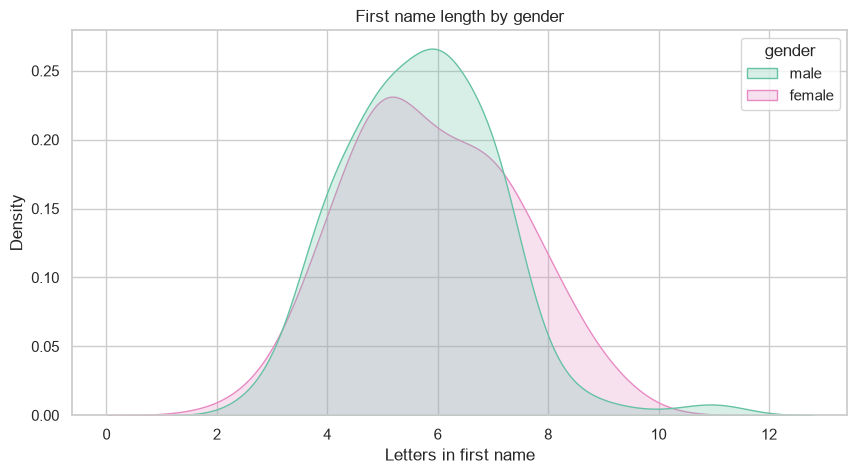

In [23]:
# Chart - 9 visualization code
# Bivariate (numerical - categorical): first name length by gender
print(labeled.groupby("gender")["name_length"].describe().round(2))

plt.figure(figsize=(10, 5))
sns.kdeplot(data=labeled, x="name_length", hue="gender", fill=True, common_norm=False,
            bw_adjust=1.5, palette={"female": "#e78ac3", "male": "#66c2a5"})
plt.title("First name length by gender")
plt.xlabel("Letters in first name")
plt.show()

##### 1. Why did you pick the specific chart?

A KDE plot draws a smooth distribution for each gender on the same axis, which makes it easy to see if one group's names are longer than the other's.

##### 2. What is/are the insight(s) found from the chart?

Female first names are only slightly longer on average, 5.89 letters against 5.70 for male names. The two curves overlap almost completely, apart from a small extra bump for female names at 8 to 9 letters.

##### 3. Will the gained insights help creating a positive business impact? 
Are there any insights that lead to negative growth? Justify with specific reason.

It tells me name length on its own is a weak feature, so the model will rely more on which letters are in the name than on how long it is. There is no direct business impact and no negative insight here.

#### Chart - 10

        n_flights  avg_flight_price
gender                             
female     204.42            951.77
male       202.77            962.48
none       203.80            954.79


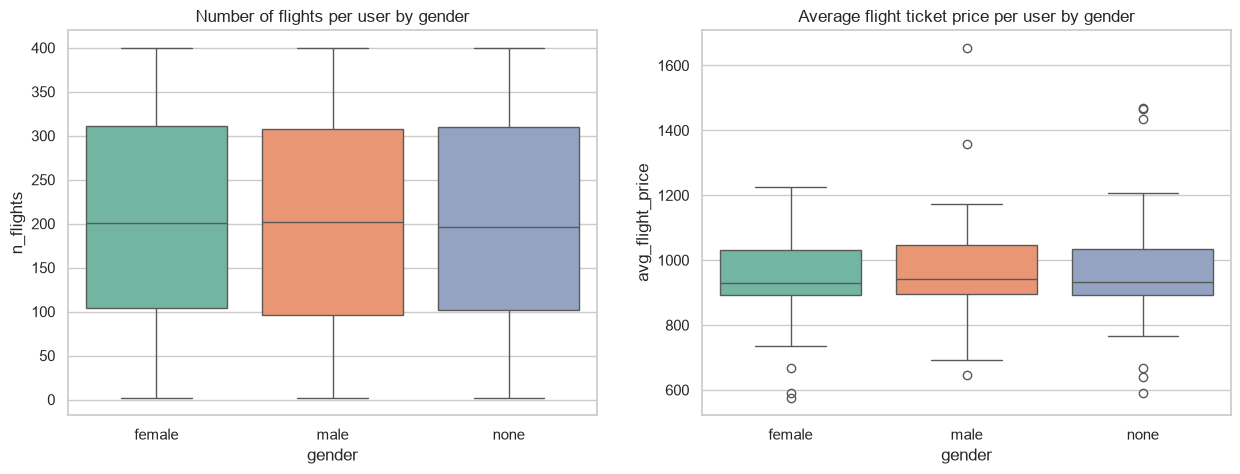

In [24]:
# Chart - 10 visualization code
# Bivariate (numerical - categorical): flight behaviour by gender
print(df.groupby("gender")[["n_flights", "avg_flight_price"]].mean().round(2))

fig, ax = plt.subplots(1, 2, figsize=(15, 5))
order = ["female", "male", "none"]
sns.boxplot(data=df, x="gender", y="n_flights", order=order, palette="Set2", ax=ax[0])
ax[0].set_title("Number of flights per user by gender")
sns.boxplot(data=df[df["n_flights"].notnull()], x="gender", y="avg_flight_price", order=order, palette="Set2", ax=ax[1])
ax[1].set_title("Average flight ticket price per user by gender")
plt.show()

##### 1. Why did you pick the specific chart?

Two box plots side by side compare the number of flights and the average ticket price per user across the gender values. Box plots make it easy to compare the middle and spread of each group.

##### 2. What is/are the insight(s) found from the chart?

Flight behaviour is the same for all genders. Women take 204.4 flights on average and men 202.8. The average ticket price is 951.8 for women and 962.5 for men. The boxes overlap almost completely.

##### 3. Will the gained insights help creating a positive business impact? 
Are there any insights that lead to negative growth? Justify with specific reason.

For the business it means men and women travel just as often and spend about the same per ticket, so there is no reason to price or target flights differently by gender. For the model it is a negative result, because flight behaviour won't help predict gender.

#### Chart - 11

flightType  economic  firstClass  premium
gender                                   
female         28.41       42.31    29.28
male           28.40       43.27    28.34
none           28.67       42.88    28.45


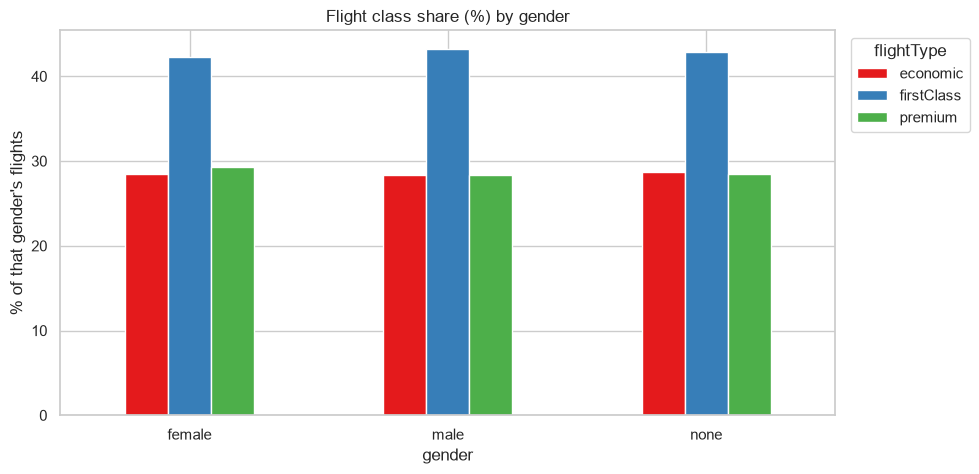

In [25]:
# Chart - 11 visualization code
# Bivariate (categorical - categorical): flight class chosen by gender, on all flight bookings
fl = flights.merge(users[["code", "gender"]], left_on="userCode", right_on="code")
class_gender = pd.crosstab(fl["gender"], fl["flightType"], normalize="index") * 100
print(class_gender.round(2))

class_gender.plot(kind="bar", figsize=(10, 5), color=sns.color_palette("Set1"))
plt.title("Flight class share (%) by gender")
plt.ylabel("% of that gender's flights")
plt.xticks(rotation=0)
plt.legend(title="flightType", bbox_to_anchor=(1.01, 1))
plt.show()

##### 1. Why did you pick the specific chart?

Flight class is a category and gender is a category, so a grouped bar chart of percentages compares the class mix for each gender. I used all 271,888 flight bookings here, not one row per user.

##### 2. What is/are the insight(s) found from the chart?

The class mix is almost identical. First class is 42.3% of female flights and 43.3% of male flights, economic is 28.4% for both, and premium is 29.3% vs 28.3%. The 'none' group looks the same too.

##### 3. Will the gained insights help creating a positive business impact? 
Are there any insights that lead to negative growth? Justify with specific reason.

It confirms that the choice of cabin class has nothing to do with gender in this data, so upselling to premium or first class should be aimed at all users the same way. No insight here leads to negative growth, but it is another feature I can drop from the model.

#### Chart - 12

        n_hotel_stays  avg_hotel_days  total_hotel_spend
gender                                                  
female          31.04            2.53           16625.76
male            30.60            2.50           16440.94
none            31.24            2.48           16737.52


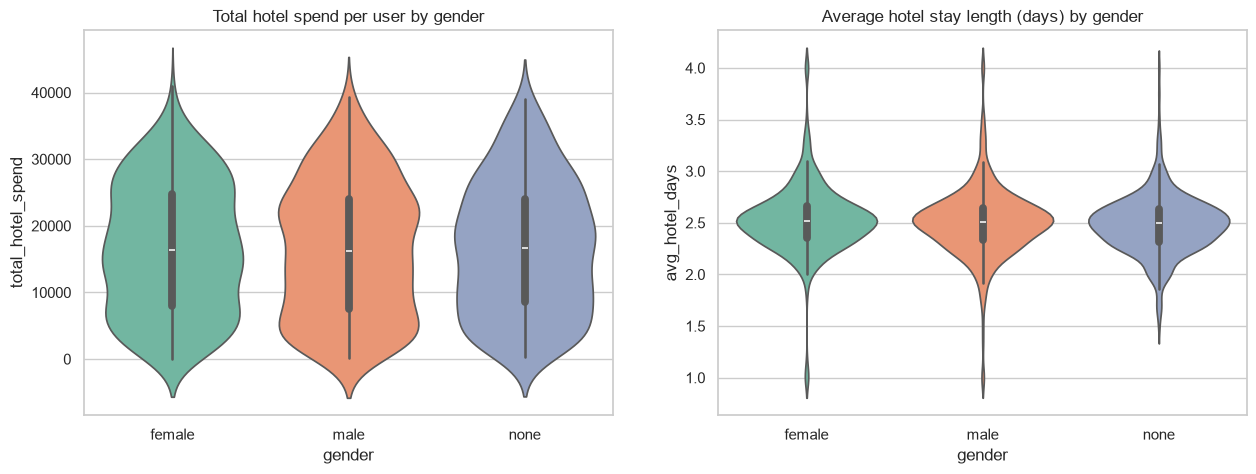

In [26]:
# Chart - 12 visualization code
# Bivariate (numerical - categorical): hotel behaviour by gender
print(df.groupby("gender")[["n_hotel_stays", "avg_hotel_days", "total_hotel_spend"]].mean().round(2))

fig, ax = plt.subplots(1, 2, figsize=(15, 5))
order = ["female", "male", "none"]
sns.violinplot(data=df, x="gender", y="total_hotel_spend", order=order, palette="Set2", ax=ax[0])
ax[0].set_title("Total hotel spend per user by gender")
sns.violinplot(data=df[df["avg_hotel_days"].notnull()], x="gender", y="avg_hotel_days", order=order, palette="Set2", ax=ax[1])
ax[1].set_title("Average hotel stay length (days) by gender")
plt.show()

##### 1. Why did you pick the specific chart?

Violin plots show the full shape of a distribution and also work like a box plot, which helps with spend values that are spread over a wide range.

##### 2. What is/are the insight(s) found from the chart?

Hotel behaviour is also very similar. Women have 31.0 hotel stays on average against 30.6 for men, they stay 2.53 vs 2.50 days, and total hotel spend is 16,626 vs 16,441. The violins have the same shape for all three gender values.

##### 3. Will the gained insights help creating a positive business impact? 
Are there any insights that lead to negative growth? Justify with specific reason.

Hotel offers don't need to be split by gender because both groups book the same way. For the gender model it is the third behaviour chart in a row with no difference, so I am fairly sure travel behaviour doesn't carry gender information in this data.

#### Chart - 13

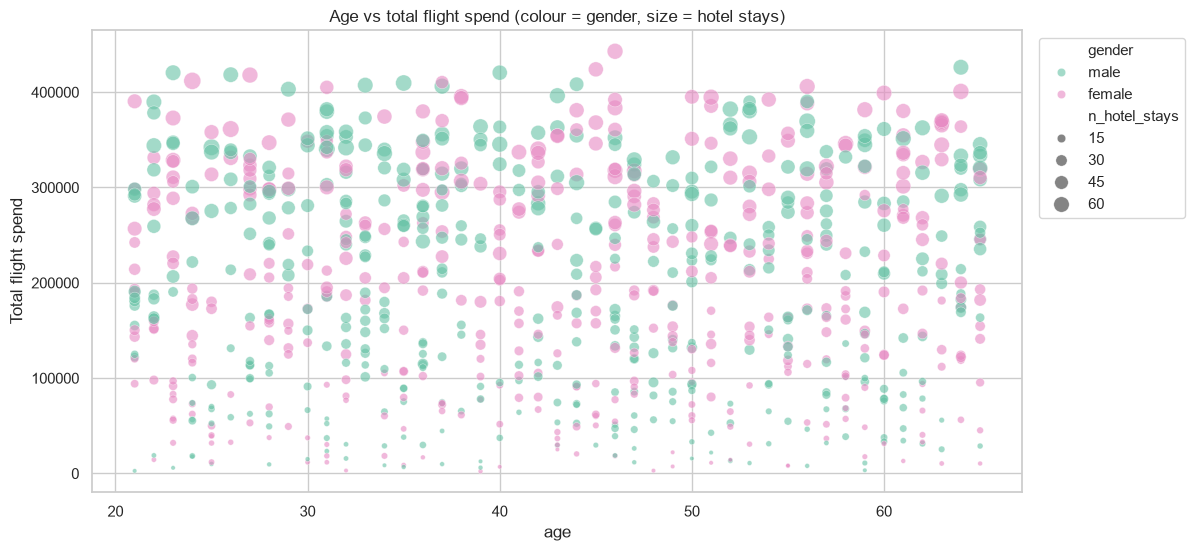

In [27]:
# Chart - 13 visualization code
# Multivariate: age vs total flight spend, coloured by gender and sized by number of hotel stays
plt.figure(figsize=(12, 6))
sns.scatterplot(data=labeled, x="age", y="total_flight_spend", hue="gender", size="n_hotel_stays",
                sizes=(10, 150), alpha=0.6, palette={"female": "#e78ac3", "male": "#66c2a5"})
plt.title("Age vs total flight spend (colour = gender, size = hotel stays)")
plt.ylabel("Total flight spend")
plt.legend(bbox_to_anchor=(1.01, 1))
plt.show()

##### 1. Why did you pick the specific chart?

A scatter plot with colour for gender and point size for hotel stays shows four variables at once. If any combination of age and spend separated men and women, it would show up as coloured clusters.

##### 2. What is/are the insight(s) found from the chart?

There are no clusters. Pink and green points are fully mixed across all ages and spend levels, and the point sizes (hotel stays) go up with flight spend for both genders the same way. Even when looking at several variables together, behaviour does not separate the genders.

##### 3. Will the gained insights help creating a positive business impact? 
Are there any insights that lead to negative growth? Justify with specific reason.

It shows that heavy travellers exist in every age group and in both genders, so loyalty programs should be based on travel volume and not on age or gender. For modelling this rules out the idea that some mix of behaviour features could work even though each one alone doesn't. Nothing negative for the business.

#### Chart - 14 - Correlation Heatmap

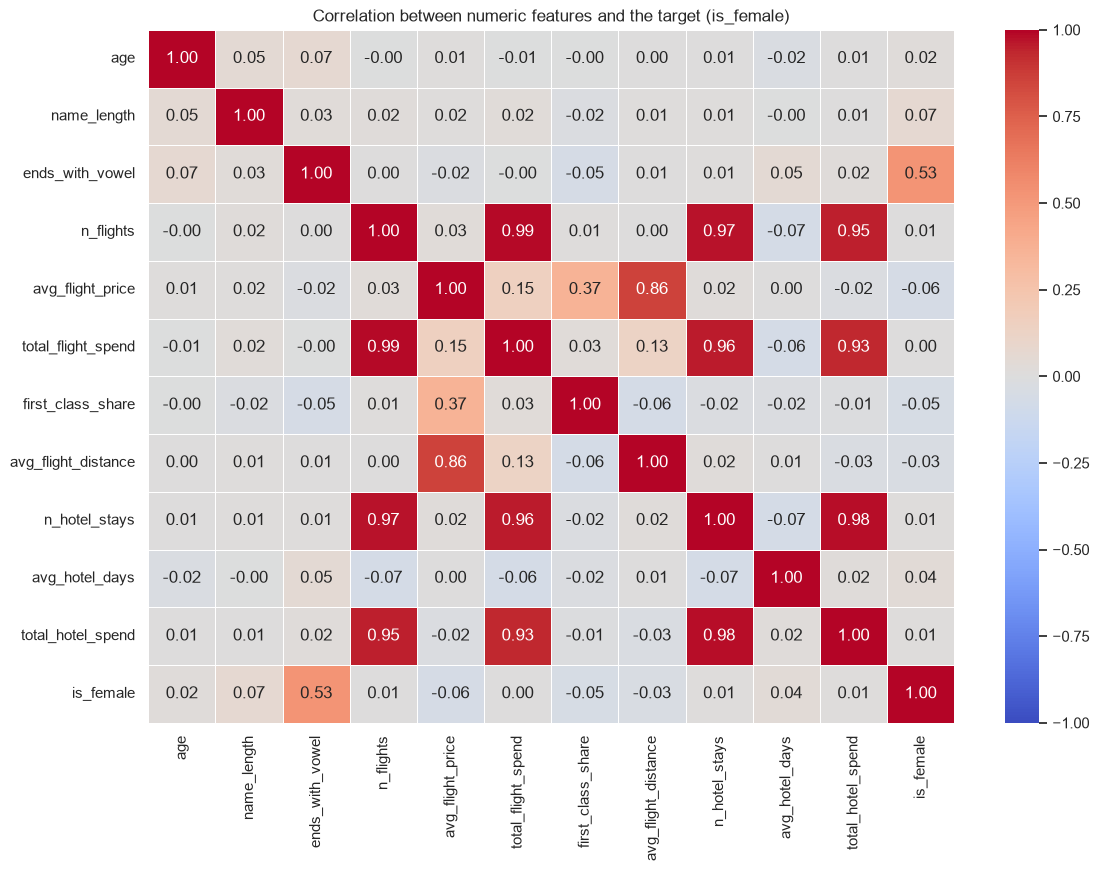

ends_with_vowel        0.527
name_length            0.065
avg_flight_price      -0.058
first_class_share     -0.053
avg_hotel_days         0.038
avg_flight_distance   -0.034
age                    0.018
n_hotel_stays          0.012
total_hotel_spend      0.009
n_flights              0.007
total_flight_spend     0.003
Name: is_female, dtype: float64


In [28]:
# Correlation Heatmap visualization code
# labeled users only, with the target turned into 0/1 so we can see if anything correlates with it
corr_df = labeled[["age", "name_length", "ends_with_vowel"] + behaviour_cols].copy()
corr_df["is_female"] = (labeled["gender"] == "female").astype(int)

plt.figure(figsize=(13, 9))
sns.heatmap(corr_df.corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, linewidths=0.5)
plt.title("Correlation between numeric features and the target (is_female)")
plt.show()

print(corr_df.corr()["is_female"].drop("is_female").sort_values(key=abs, ascending=False).round(3))

##### 1. Why did you pick the specific chart?

A correlation heatmap shows the linear relationship between every pair of numeric columns in one picture. I added the target as a 0/1 column (is_female) so I can see straight away which features are related to it.

##### 2. What is/are the insight(s) found from the chart?

- ends_with_vowel has a correlation of 0.527 with is_female, which is by far the strongest. Everything else is weak: name_length 0.065, and all the behaviour columns and age are below 0.06 in absolute value.
- The behaviour columns are strongly correlated with each other. n_flights and total_flight_spend are 0.99 and n_hotel_stays and total_hotel_spend are 0.98. They basically measure the same thing (how much someone travels), so I remove the duplicates in feature selection.

#### Chart - 15 - Pair Plot 

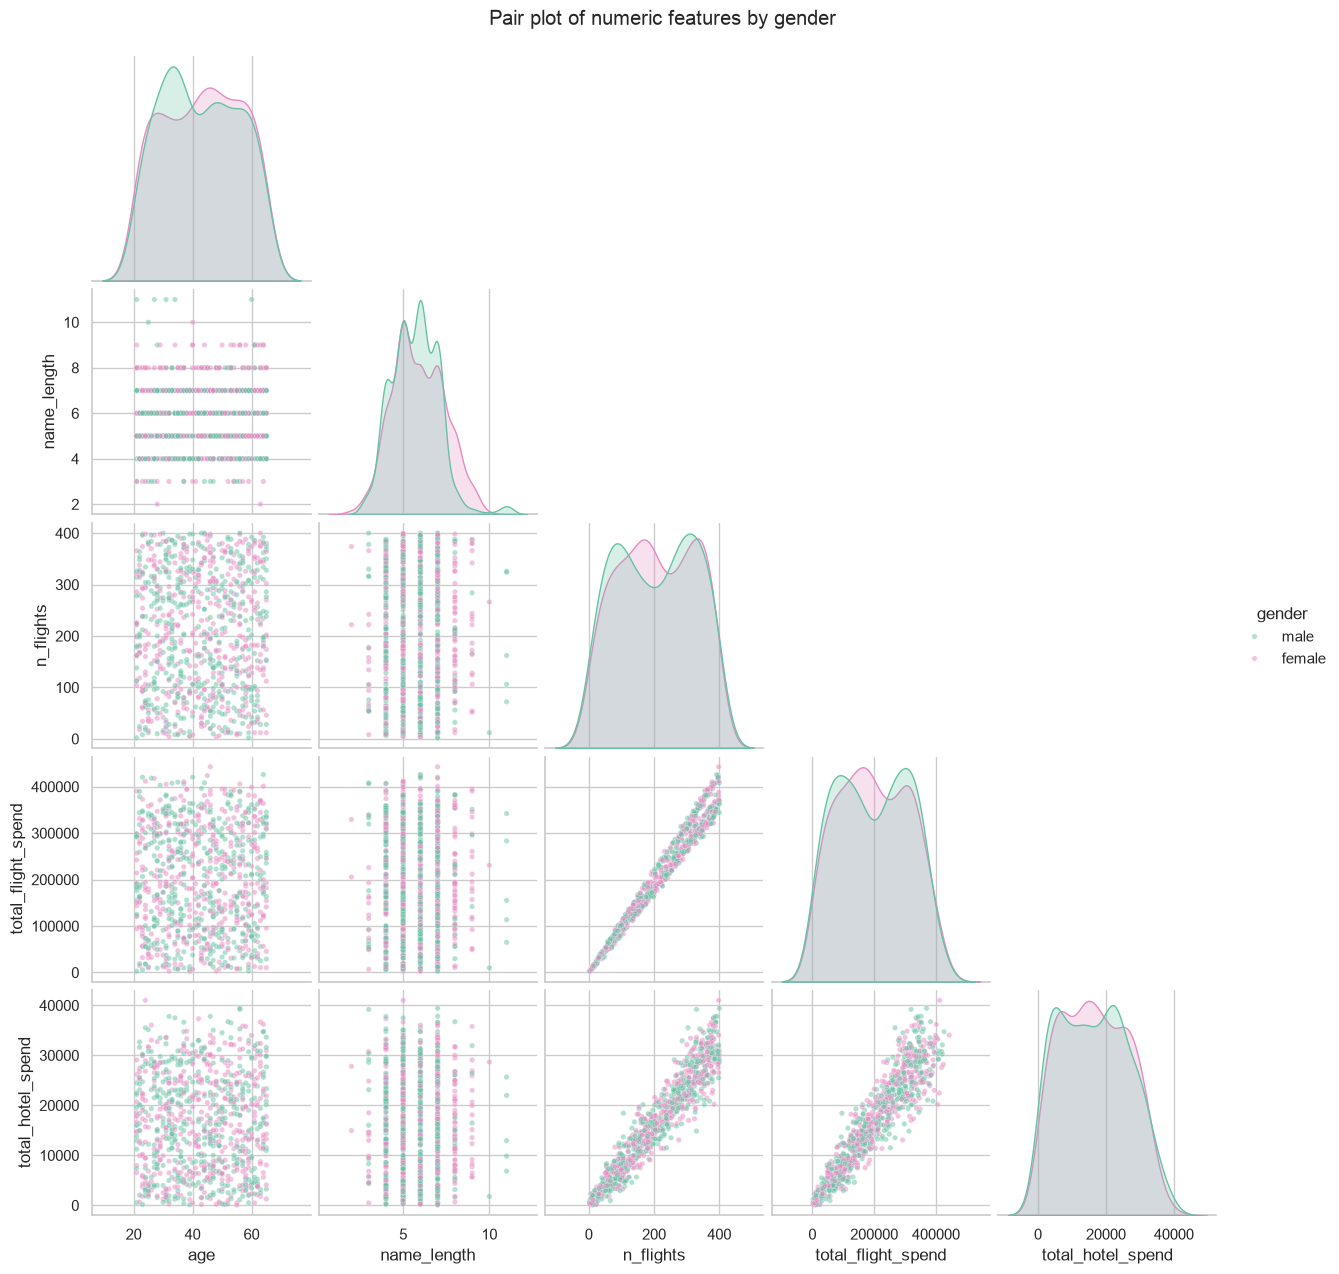

In [29]:
# Pair Plot visualization code
pair_cols = ["age", "name_length", "n_flights", "total_flight_spend", "total_hotel_spend"]
sns.pairplot(labeled[pair_cols + ["gender"]].dropna(), hue="gender", corner=True,
             palette={"female": "#e78ac3", "male": "#66c2a5"}, plot_kws={"alpha": 0.5, "s": 15})
plt.suptitle("Pair plot of numeric features by gender", y=1.02)
plt.show()

##### 1. Why did you pick the specific chart?

A pair plot shows the scatter plot of every pair of numeric features and the distribution of each one, split by gender. It is a quick way to check for any separation between the classes in many features at once.

##### 2. What is/are the insight(s) found from the chart?

For age, name length, number of flights and total spend the female and male distributions sit on top of each other, both on the diagonal and in the scatter plots. The clear straight lines between n_flights, total_flight_spend and total_hotel_spend show again that these features are almost the same information. Only name_length shows a slight shift, with more female names at 8 to 9 letters.

## ***5. Hypothesis Testing***

### Based on your chart experiments, define three hypothetical statements from the dataset. In the next three questions, perform hypothesis testing to obtain final conclusion about the statements through your code and statistical testing.

From the charts I picked three statements to test:

1. Male and female users have the same average age (chart 6).
2. Gender is independent of the company a user belongs to (chart 7).
3. Whether a first name ends with a vowel is independent of gender (chart 8 and the heatmap).

The first two are about features I think are useless, and the third is about the feature I think is useful, so together they back up my feature selection with statistics and not only charts.

### Hypothetical Statement - 1

#### 1. State Your research hypothesis as a null hypothesis and alternate hypothesis.

- **Null hypothesis (H0):** the mean age of female users is equal to the mean age of male users.
- **Alternative hypothesis (H1):** the mean ages are different.

Significance level: 0.05

#### 2. Perform an appropriate statistical test.

In [30]:
# Perform Statistical Test to obtain P-Value
female_age = labeled.loc[labeled["gender"] == "female", "age"]
male_age = labeled.loc[labeled["gender"] == "male", "age"]

# Welch's t-test (does not assume equal variances)
t_stat, p_value = stats.ttest_ind(female_age, male_age, equal_var=False)
print(f"Mean age female: {female_age.mean():.2f} | male: {male_age.mean():.2f}")
print(f"t statistic = {t_stat:.3f}, p-value = {p_value:.4f}")

# Levene's test just to check the variance assumption
print(f"Levene test p-value (equal variances): {stats.levene(female_age, male_age).pvalue:.4f}")
print("Reject H0" if p_value < 0.05 else "Fail to reject H0: no significant age difference between genders")

Mean age female: 43.18 | male: 42.70
t statistic = 0.552, p-value = 0.5808
Levene test p-value (equal variances): 0.8772
Fail to reject H0: no significant age difference between genders


##### Which statistical test have you done to obtain P-Value?

I used Welch's two sample t-test (scipy.stats.ttest_ind with equal_var=False). The p-value is 0.5808 (t = 0.552), which is much larger than 0.05, so I fail to reject H0. There is no significant difference in age between female (43.18) and male (42.70) users.

##### Why did you choose the specific statistical test?

I am comparing the mean of a numeric variable between two independent groups, which is what a two sample t-test is for. I used Welch's version because it does not assume equal variances, so it is the safer choice (Levene's test gave p = 0.877, so the variances are close anyway). With about 450 users in each group the central limit theorem makes the t-test valid even though age is not normally distributed.

### Hypothetical Statement - 2

#### 1. State Your research hypothesis as a null hypothesis and alternate hypothesis.

- **Null hypothesis (H0):** gender (male/female) is independent of company.
- **Alternative hypothesis (H1):** gender depends on company.

Significance level: 0.05

#### 2. Perform an appropriate statistical test.

In [31]:
# Perform Statistical Test to obtain P-Value
contingency = pd.crosstab(labeled["company"], labeled["gender"])
print(contingency, "\n")

chi2_stat, p_value, dof, expected = stats.chi2_contingency(contingency)
print(f"chi-square = {chi2_stat:.3f}, dof = {dof}, p-value = {p_value:.4f}")
print("Smallest expected count:", expected.min().round(1))
print("Reject H0" if p_value < 0.05 else "Fail to reject H0: gender looks independent of company")

gender         female  male
company                    
4You              151   138
Acme Factory       85    93
Monsters CYA       64    61
Umbrella LTDA      69    70
Wonka Company      79    90 

chi-square = 1.722, dof = 4, p-value = 0.7868
Smallest expected count: 62.2
Fail to reject H0: gender looks independent of company


##### Which statistical test have you done to obtain P-Value?

I used the chi-square test of independence (scipy.stats.chi2_contingency) on the company x gender table. The result was chi-square = 1.722 with 4 degrees of freedom and a p-value of 0.7868, so I fail to reject H0. Gender looks independent of company.

##### Why did you choose the specific statistical test?

Both variables are categorical, and the chi-square test of independence checks whether the counts in a contingency table are different from what we would expect if the two variables were unrelated. Its assumption is that expected counts are at least 5, and here the smallest expected count is 62.2, so the test is valid.

### Hypothetical Statement - 3

#### 1. State Your research hypothesis as a null hypothesis and alternate hypothesis.

- **Null hypothesis (H0):** whether a first name ends with a vowel is independent of gender.
- **Alternative hypothesis (H1):** names ending with a vowel and gender are related.

Significance level: 0.05

#### 2. Perform an appropriate statistical test.

In [32]:
# Perform Statistical Test to obtain P-Value
contingency = pd.crosstab(labeled["ends_with_vowel"].map({1: "ends with vowel", 0: "ends with consonant"}),
                          labeled["gender"])
print(contingency, "\n")

chi2_stat, p_value, dof, expected = stats.chi2_contingency(contingency)
print(f"chi-square = {chi2_stat:.3f}, dof = {dof}, p-value = {p_value:.3e}")
# Cramer's V to see how strong the association is, not only if it exists
cramers_v = np.sqrt(chi2_stat / (contingency.values.sum() * (min(contingency.shape) - 1)))
print(f"Cramer's V = {cramers_v:.3f}")
print("Reject H0: name ending and gender are related" if p_value < 0.05 else "Fail to reject H0")

gender               female  male
ends_with_vowel                  
ends with consonant     174   404
ends with vowel         274    48 

chi-square = 247.936, dof = 1, p-value = 7.318e-56
Cramer's V = 0.525
Reject H0: name ending and gender are related


##### Which statistical test have you done to obtain P-Value?

Again a chi-square test of independence, on a 2 x 2 table. Names ending with a vowel are 274 female vs 48 male, and names ending with a consonant are 174 female vs 404 male. The chi-square value is 247.9 and the p-value is 7.3e-56, which is basically zero, so I reject H0. I also calculated Cramer's V = 0.525, which means the association is strong and not only statistically significant.

##### Why did you choose the specific statistical test?

Both variables are categorical (vowel / consonant ending and female / male), so the chi-square test of independence is the right test. I added Cramer's V because with 900 users even a small effect can give a tiny p-value. Cramer's V tells how strong the relationship is, and 0.525 is a strong one. This supports using the letters of the first name as the main input for the model.

## ***6. Feature Engineering & Data Pre-processing***

### 1. Handling Missing Values

In [33]:
# Handling Missing Values & Missing Value Imputation
# users.csv has no nulls. The only nulls came from the left join with flights/hotels,
# for users who never booked a flight or a hotel. For them the right value is simply 0 activity.
print("Nulls before imputation:", df[behaviour_cols].isnull().sum().sum())
df[behaviour_cols] = df[behaviour_cols].fillna(0)
print("Nulls after imputation :", df.isnull().sum().sum())

# refresh the labeled / unlabeled splits so they have the filled values
labeled = df[df["gender"] != "none"].reset_index(drop=True)
unlabeled = df[df["gender"] == "none"].reset_index(drop=True)

Nulls before imputation: 115
Nulls after imputation : 0


#### What all missing value imputation techniques have you used and why did you use those techniques?

users.csv itself has no missing values. The only nulls (115 in total) came from the left join with the booking tables: 5 users have no flights, so their 5 flight columns are empty, and 30 users have no hotel stays, so their 3 hotel columns are empty.

I filled these with 0. A user with no bookings really has 0 flights and 0 spend, so 0 is the true value and not a guess. Using the mean or median would have invented travel activity that never happened. For the average columns (like average ticket price) 0 is not perfect, but it only affects a handful of users and these behaviour columns are dropped from the final model anyway.

### 2. Handling Outliers

In [34]:
# Handling Outliers & Outlier treatments
# count values outside 1.5 * IQR for each numeric column (labeled users)
num_cols = ["age", "name_length"] + behaviour_cols
outlier_counts = {}
for col in num_cols:
    q1, q3 = labeled[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    outlier_counts[col] = int(((labeled[col] < q1 - 1.5 * iqr) | (labeled[col] > q3 + 1.5 * iqr)).sum())
print(pd.Series(outlier_counts, name="outliers (IQR rule)"))

# the shortest and longest first names, to check they are real names and not data errors
print("\nShortest names:", labeled.loc[labeled["name_length"] <= 3, "first_name"].unique().tolist())
print("Longest names :", labeled.loc[labeled["name_length"] >= 10, "first_name"].unique().tolist())

age                     0
name_length             5
n_flights               0
avg_flight_price        8
total_flight_spend      0
first_class_share      62
avg_flight_distance     3
n_hotel_stays           0
avg_hotel_days         63
total_hotel_spend       0
Name: outliers (IQR rule), dtype: int64

Shortest names: ['Roy', 'Ida', 'Ann', 'Kim', 'Rae', 'Ma', 'Rex', 'Eva', 'Ora', 'Ray', 'Sam', 'Ima', 'Amy', 'Kia', 'Tim', 'Ben', 'Tad', 'Ted', 'Guy', 'Zoe']
Longest names : ['Christopher', 'Jacqueline', 'Kristopher']


##### What all outlier treatment techniques have you used and why did you use those techniques?

I counted outliers with the IQR rule (values outside 1.5 x IQR). Age has none. Some behaviour columns have outliers, for example first_class_share (62) and avg_hotel_days (63), and name_length has 5 (the two letter and eleven letter names).

I did not remove or cap any of them. When I checked them they are real values: users who almost always fly first class, users with only one or two hotel stays, and real names like "Ma", "Christopher" and "Kristopher". Removing them would mean throwing away real users. The final model also only uses the first name text, which these numeric outliers don't affect.

### 3. Categorical Encoding

In [35]:
# Encode your categorical columns
# target: keep the text labels for the models, plus a 0/1 version for correlation and ROC-AUC
labeled["is_female"] = (labeled["gender"] == "female").astype(int)
print(labeled[["gender", "is_female"]].drop_duplicates())

# company is nominal with only 5 values, so one-hot encoding (used in the behaviour baseline model)
company_dummies = pd.get_dummies(labeled["company"], prefix="company", dtype=int)
company_dummies.head()

   gender  is_female
0    male          0
2  female          1


,company_4You,company_Acme Factory,company_Monsters CYA,company_Umbrella LTDA,company_Wonka Company
0,1,0,0,0,0
1,1,0,0,0,0
2,1,0,0,0,0
3,1,0,0,0,0
4,1,0,0,0,0


#### What all categorical encoding techniques have you used & why did you use those techniques?

- Target (gender): I kept the text labels "female" and "male" for the models, since scikit-learn classifiers accept string labels and the predictions are easier to read. I also made a 0/1 column (is_female) for the correlation heatmap and for ROC-AUC.
- Company: this is a nominal variable with only 5 values and no order between them, so I used one-hot encoding. Label encoding would make up a fake order (like 4You < Acme). It is only used in the behaviour baseline model.
- First name: this is the real input. It has hundreds of unique values, so one-hot encoding the whole name would not work for new names. Instead I turn it into character n-grams with TF-IDF (in the text vectorization section), which can be seen as the encoding for this column.

### 4. Textual Data Preprocessing 
(It's mandatory for textual dataset i.e., NLP, Sentiment Analysis, Text Clustering etc.)

#### 1. Expand Contraction

In [36]:
# Expand Contraction
# names don't contain contractions like "don't" or "it's", just confirming there are no apostrophes
print("Names containing an apostrophe:", df["name"].str.contains("'").sum())

Names containing an apostrophe: 0


#### 2. Lower Casing

In [37]:
# Lower Casing
# "Maria" and "maria" should be the same name for the model
df["name_clean"] = df["name"].str.lower()
df[["name", "name_clean"]].head()

,name,name_clean
0,Roy Braun,roy braun
1,Joseph Holsten,joseph holsten
2,Wilma Mcinnis,wilma mcinnis
3,Paula Daniel,paula daniel
4,Patricia Carson,patricia carson


#### 3. Removing Punctuations

In [38]:
# Remove Punctuations
before = df["name_clean"].copy()
df["name_clean"] = df["name_clean"].str.replace(r"[^\w\s]", "", regex=True)
print("Names changed by removing punctuation:", (before != df["name_clean"]).sum())

Names changed by removing punctuation: 0


#### 4. Removing URLs & Removing words and digits contain digits.

In [39]:
# Remove URLs & Remove words and digits contain digits
before = df["name_clean"].copy()
df["name_clean"] = df["name_clean"].str.replace(r"http\S+|www\.\S+", "", regex=True)
df["name_clean"] = df["name_clean"].str.replace(r"\w*\d\w*", "", regex=True)
print("Names changed by removing URLs/digits:", (before != df["name_clean"]).sum())

Names changed by removing URLs/digits: 0


#### 5. Removing Stopwords & Removing White spaces

In [40]:
# Remove Stopwords
# not applicable: a person's name has no stopwords like "the", "and", "is"
print("Skipped, names have no stopwords")

Skipped, names have no stopwords


In [41]:
# Remove White spaces
df["name_clean"] = df["name_clean"].str.strip().str.replace(r"\s+", " ", regex=True)
print("Names with leading/trailing spaces left:", (df["name_clean"] != df["name_clean"].str.strip()).sum())

Names with leading/trailing spaces left: 0


#### 6. Rephrase Text

In [42]:
# Rephrase Text
# not applicable: there is nothing to rephrase in a name, changing it would change the person
print("Skipped, names are kept as they are")

Skipped, names are kept as they are


#### 7. Tokenization

In [43]:
# Tokenization
# split the full name into word tokens and keep the first token (first name) as the model input
df["name_tokens"] = df["name_clean"].str.split(" ")
df["first_name_clean"] = df["name_tokens"].str[0]
print(df[["name", "name_tokens", "first_name_clean"]].head(8))

              name         name_tokens first_name_clean
0        Roy Braun        [roy, braun]              roy
1   Joseph Holsten   [joseph, holsten]           joseph
2    Wilma Mcinnis    [wilma, mcinnis]            wilma
3     Paula Daniel     [paula, daniel]            paula
4  Patricia Carson  [patricia, carson]         patricia
5     Trina Thomas     [trina, thomas]            trina
6    Jesse Decelle    [jesse, decelle]            jesse
7     Gregoria Gil     [gregoria, gil]         gregoria


#### 8. Text Normalization

In [44]:
# Normalizing Text (i.e., Stemming, Lemmatization etc.)
# unicode normalization: turns accented letters into plain ones (e.g. "jose" with an accent -> "jose"),
# so the same name written two ways gives the same n-grams. Most names here are plain ascii already.
def strip_accents(text):
    return unicodedata.normalize("NFKD", text).encode("ascii", "ignore").decode("ascii")

before = df["first_name_clean"].copy()
df["first_name_clean"] = df["first_name_clean"].apply(strip_accents)
print("Names changed by unicode normalization:", (before != df["first_name_clean"]).sum())

# all of the cleaning steps above in one function, used later for brand new names
def to_first_name(full_name):
    text = strip_accents(str(full_name)).lower()
    text = re.sub(r"[^\w\s]", "", text)
    text = re.sub(r"\w*\d\w*", "", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text.split(" ")[0] if text else ""

# quick check that the function gives exactly the same result as the step by step cleaning
print("Function matches step by step cleaning:", (df["name"].apply(to_first_name) == df["first_name_clean"]).all())

labeled = df[df["gender"] != "none"].reset_index(drop=True)
unlabeled = df[df["gender"] == "none"].reset_index(drop=True)

Names changed by unicode normalization: 0
Function matches step by step cleaning: True


##### Which text normalization technique have you used and why?

I only used unicode normalization (NFKD), which turns accented letters into plain letters, for example an accented "jose" becomes "jose". This way the same name written with or without accents gives the same n-grams. All the names in this data are plain ascii already, so 0 names changed, but the step matters for new users typing their names in the app.

I did not use stemming or lemmatization on purpose. Those methods cut off word endings, and for names the ending is exactly what tells the gender ("maria" vs "mario", "daniela" vs "daniel"). A stemmer would throw away the most useful part of the input. I also wrapped all the cleaning steps into one function, to_first_name(), and checked that it gives the same result as the step by step cleaning for all 1340 users, so new names get exactly the same treatment.

#### 9. Part of speech tagging

In [45]:
# POS Taging
# not applicable: every token is a proper noun (a name), so POS tags would all be the same
print("Skipped, all tokens are proper nouns")

Skipped, all tokens are proper nouns


#### 10. Text Vectorization

In [46]:
# Vectorizing Text
# character n-grams inside word boundaries: "maria" -> " m", "ma", "ar", ..., "ia", "a ", " ma", ...
# This only shows what the vectorizer produces. In the models it sits inside a Pipeline and is fit on training data only.
demo_vec = TfidfVectorizer(analyzer="char_wb", ngram_range=(1, 4))
demo_matrix = demo_vec.fit_transform(labeled["first_name_clean"])
print("TF-IDF matrix shape (names x n-grams):", demo_matrix.shape)
print("Non zero values per name (avg):", round(demo_matrix.getnnz(axis=1).mean(), 1))

example = demo_vec.transform(["maria"])
features = demo_vec.get_feature_names_out()
print("\nN-grams of 'maria' and their tf-idf weights:")
print(pd.Series(example.toarray()[0], index=features).loc[lambda s: s > 0].sort_values(ascending=False).round(3).to_string())

TF-IDF matrix shape (names x n-grams): (900, 3012)
Non zero values per name (avg): 23.5

N-grams of 'maria' and their tf-idf weights:
ria     0.356
aria    0.356
ria     0.305
mari    0.300
ari     0.286
ia      0.242
 mar    0.225
mar     0.223
 ma     0.211
ia      0.207
ma      0.194
ri      0.189
 m      0.180
ar      0.165
a       0.162
a       0.148
m       0.145
        0.111
i       0.108
r       0.099


##### Which text vectorization technique have you used and why?

I used TF-IDF on character n-grams with analyzer="char_wb" and n-grams of 1 to 4 characters (the n-gram range is tuned later with GridSearchCV).

Why character n-grams and not words: every user has only one first name, so a word level bag of words would just be a lookup table of known names and would fail on any new name. Character n-grams break a name into small pieces like "ia", "ria" and "a " (the space marks the end of the word), and these pieces are shared between names. That lets the model learn that names ending in "a" or "ia" are usually female, even for names it has never seen. "char_wb" adds the word boundary, so endings and beginnings get their own features.

Why TF-IDF: it gives less weight to n-grams that appear in almost every name, like single vowels, and more weight to rarer pieces. It also L2-normalises every name vector. On the 900 labeled names this gives a 900 x 3012 sparse matrix with about 23.5 non zero values per name.

### 4. Feature Manipulation & Selection

#### 1. Feature Manipulation

In [47]:
# Manipulate Features to minimize feature correlation and create new features
# extra name features: last two / three letters and the share of vowels
labeled["last_two"] = labeled["first_name_clean"].str[-2:]
labeled["last_three"] = labeled["first_name_clean"].str[-3:]
labeled["vowel_ratio"] = labeled["first_name_clean"].apply(lambda s: sum(ch in VOWELS for ch in s) / len(s))
print(labeled[["first_name_clean", "last_letter", "last_two", "last_three", "vowel_ratio", "gender"]].head(8))

# behaviour features that are almost copies of each other
beh_corr = labeled[behaviour_cols].corr().abs()
pairs = [(a, b, round(beh_corr.loc[a, b], 3)) for i, a in enumerate(behaviour_cols)
         for b in behaviour_cols[i + 1:] if beh_corr.loc[a, b] > 0.8]
print("\nHighly correlated behaviour pairs (> 0.8):", pairs)

# keep one column from each correlated pair
behaviour_features = ["n_flights", "avg_flight_price", "first_class_share", "avg_flight_distance",
                      "n_hotel_stays", "avg_hotel_days"]
print("Behaviour features kept:", behaviour_features)

  first_name_clean last_letter last_two last_three  vowel_ratio  gender
0              roy           y       oy        roy     0.333333    male
1           joseph           h       ph        eph     0.333333    male
2            wilma           a       ma        lma     0.400000  female
3            paula           a       la        ula     0.600000  female
4         patricia           a       ia        cia     0.500000  female
5            jesse           e       se        sse     0.400000    male
6         gregoria           a       ia        ria     0.500000  female
7           melvin           n       in        vin     0.333333    male

Highly correlated behaviour pairs (> 0.8): [('n_flights', 'total_flight_spend', np.float64(0.988)), ('n_flights', 'n_hotel_stays', np.float64(0.971)), ('n_flights', 'total_hotel_spend', np.float64(0.954)), ('avg_flight_price', 'avg_flight_distance', np.float64(0.854)), ('total_flight_spend', 'n_hotel_stays', np.float64(0.961)), ('total_flight_spend'

#### 2. Feature Selection

A) age + company + behaviour (LogReg)          0.472
A) age + company + behaviour (RandomForest)    0.491
B) hand made name features (LogReg)            0.858
C) first name char n-grams (LogReg)            0.884
dtype: float64


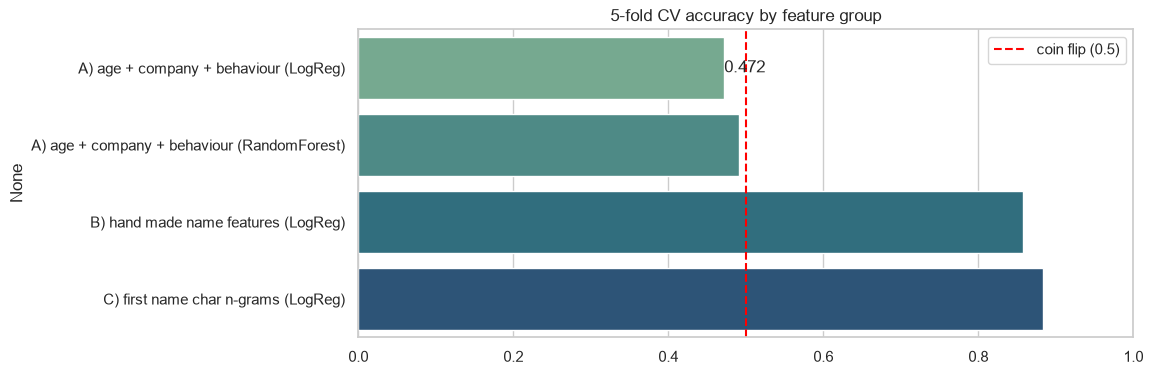

In [48]:
# Select your features wisely to avoid overfitting
# Same 5-fold CV for three different feature groups, to see which one actually carries information
cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
y_all = labeled["gender"]

# A) age + company + travel behaviour
behaviour_pipe = Pipeline([
    ("prep", ColumnTransformer([("num", StandardScaler(), ["age"] + behaviour_features),
                                ("cat", OneHotEncoder(handle_unknown="ignore"), ["company"])])),
    ("clf", LogisticRegression(max_iter=2000))])
behaviour_rf = Pipeline([
    ("prep", ColumnTransformer([("num", "passthrough", ["age"] + behaviour_features),
                                ("cat", OneHotEncoder(handle_unknown="ignore"), ["company"])])),
    ("clf", RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1))])

# B) hand made name features
name_feat_pipe = Pipeline([
    ("prep", ColumnTransformer([("cat", OneHotEncoder(handle_unknown="ignore"), ["last_letter", "last_two", "last_three"]),
                                ("num", StandardScaler(), ["name_length", "vowel_ratio"])])),
    ("clf", LogisticRegression(max_iter=2000))])

# C) character n-grams of the first name
ngram_pipe = Pipeline([("tfidf", TfidfVectorizer(analyzer="char_wb", ngram_range=(1, 4))),
                       ("clf", LogisticRegression(max_iter=2000))])

selection = {
    "A) age + company + behaviour (LogReg)": cross_val_score(behaviour_pipe, labeled, y_all, cv=cv5).mean(),
    "A) age + company + behaviour (RandomForest)": cross_val_score(behaviour_rf, labeled, y_all, cv=cv5).mean(),
    "B) hand made name features (LogReg)": cross_val_score(name_feat_pipe, labeled, y_all, cv=cv5).mean(),
    "C) first name char n-grams (LogReg)": cross_val_score(ngram_pipe, labeled["first_name_clean"], y_all, cv=cv5).mean(),
}
selection = pd.Series(selection).round(3)
print(selection)

plt.figure(figsize=(10, 4))
ax = sns.barplot(x=selection.values, y=selection.index, palette="crest")
ax.bar_label(ax.containers[0], fmt="%.3f")
plt.axvline(0.5, color="red", linestyle="--", label="coin flip (0.5)")
plt.xlim(0, 1)
plt.title("5-fold CV accuracy by feature group")
plt.legend()
plt.show()

In [49]:
# chi-square score of every n-gram against the target, the higher the more the n-gram tells about gender
chi_vec = CountVectorizer(analyzer="char_wb", ngram_range=(1, 4), binary=True)
chi_X = chi_vec.fit_transform(labeled["first_name_clean"])
chi_scores, chi_p = chi2(chi_X, y_all)
chi_table = pd.DataFrame({"ngram": chi_vec.get_feature_names_out(), "chi2": chi_scores, "p_value": chi_p})
female_rate = pd.Series(np.asarray(chi_X[(y_all == "female").values].sum(axis=0)).ravel() /
                        np.asarray(chi_X.sum(axis=0)).ravel(), index=chi_table.index)
chi_table["female_share"] = female_rate.round(2)
print("Total n-grams:", len(chi_table), "| significant at 5%:", (chi_table["p_value"] < 0.05).sum())
chi_table.sort_values("chi2", ascending=False).head(15).round(4)

Total n-grams: 3012 | significant at 5%: 589


,ngram,chi2,p_value,female_share
445,a,162.5679,0.0,0.99
898,d,41.2633,0.0,0.06
997,e,30.8609,0.0,0.74
1426,ia,30.2679,0.0,1.00
1966,na,28.2500,0.0,1.00
2894,w,28.2175,0.0,0.14
2491,rt,26.7611,0.0,0.00
1168,ert,25.7699,0.0,0.00
2538,sa,22.7679,0.0,0.88
2296,ra,22.1964,0.0,1.00


##### What all feature selection methods have you used  and why?

I used three feature selection methods:

1. Comparing feature groups with cross validation (wrapper style): I trained the same kind of model on three feature groups with 5-fold stratified CV. Age + company + behaviour got 47.2% accuracy with logistic regression and 49.1% with random forest, which is no better than guessing. Hand made name features (last 1/2/3 letters, length, vowel ratio) got 85.8%, and character n-grams of the first name got 88.4%. This is the most direct test of which features actually help.
2. Correlation filter: inside the behaviour columns I removed one feature from each pair with correlation above 0.8 (for example total_flight_spend, which is 0.99 correlated with n_flights), so the baseline was not just counting the same thing twice.
3. Chi-square test on n-grams (filter method): I scored every one of the 3012 n-grams against the target. 589 of them are significant at the 5% level, and the top ones are endings like "a " (99% female), "d " (6% female), "ia " and "na ".

Together these show the model should use the first name and nothing else. Keeping useless features would only add noise and make overfitting more likely.

##### Which all features you found important and why?

The important feature is the first name, and more specifically its character n-grams. The chi-square scores and the model coefficients agree that the ending of the name matters most:

- "a " (name ends in a) has the highest chi-square score (162.6) and 99% of names with it are female.
- "ia ", "na ", "ra " and "e " also point strongly to female.
- "d ", "rt", "ert", "bert" (Robert, Albert) and "k " point strongly to male.

These make sense from what we know about English and Latin names, where many female names end in -a and -ie while male names end in consonants. Age, company and all the travel behaviour features turned out to be unimportant. Every test I ran, the charts, the t-test, the chi-square test and the CV comparison, showed they don't carry information about gender.

### 5. Data Transformation

#### Do you think that your data needs to be transformed? If yes, which transformation have you used. Explain Why?

In [50]:
# Transform Your data
# The final input is text, and the transformation is text -> numbers with TF-IDF on character n-grams.
# Checking the skew of the numeric columns anyway, to justify not log-transforming them.
print(labeled[["age", "name_length"] + behaviour_features].skew().round(3))

age                    0.003
name_length            0.376
n_flights             -0.037
avg_flight_price      -1.388
first_class_share      0.534
avg_flight_distance    0.045
n_hotel_stays          0.068
avg_hotel_days        -2.467
dtype: float64


The input of the final model is text, so the transformation it needs is the TF-IDF vectorization from the section above, which turns every first name into numbers. I didn't apply any other transformation.

I did check the numeric columns. avg_hotel_days (-2.47) and avg_flight_price (-1.39) are skewed, so a log or power transform would be the normal fix if I used them. But feature selection showed that age, company and behaviour give no better than coin flip accuracy, so these columns are not part of the final model and transforming them would not change anything.

### 6. Data Scaling

In [51]:
# Scaling your data
# TF-IDF already L2-normalises every row, so each name vector has length 1 and no extra scaler is needed
row_norms = np.sqrt(np.asarray(demo_matrix.multiply(demo_matrix).sum(axis=1))).ravel()
print("Row norm of the TF-IDF vectors -> min:", row_norms.min().round(4), "max:", row_norms.max().round(4))

Row norm of the TF-IDF vectors -> min: 1.0 max: 1.0


##### Which method have you used to scale you data and why?

I didn't need a separate scaler. TF-IDF already L2-normalises each row, and the output above shows every name vector has a length of exactly 1.0 (min and max both 1.0). Every name is on the same scale no matter how long it is.

StandardScaler was only used inside the behaviour baseline pipeline in feature selection, because age and spend are on very different scales and logistic regression is sensitive to that. That pipeline is not used in the final model.

### 7. Dimesionality Reduction

##### Do you think that dimensionality reduction is needed? Explain Why?

No, not really. After vectorization there are about 3000 n-gram features for 900 names, but the matrix is very sparse (around 23 non zero values per name). Logistic regression with L2 regularization handles this kind of data well.

To check, I tried TruncatedSVD (PCA for sparse data) before logistic regression. CV accuracy dropped from 88.4% with no reduction to 77.0% with 50 components, 80.9% with 100 and 85.1% with 200. Compressing the n-grams mixes together the specific endings the model needs, so reducing dimensions only loses information here.

In [52]:
# DImensionality Reduction (If needed)
# trying TruncatedSVD (PCA for sparse data) before logistic regression, compared to no reduction
svd_results = {"no reduction": cross_val_score(ngram_pipe, labeled["first_name_clean"], y_all, cv=cv5).mean()}
for k in [50, 100, 200]:
    svd_pipe = Pipeline([("tfidf", TfidfVectorizer(analyzer="char_wb", ngram_range=(1, 4))),
                         ("svd", TruncatedSVD(n_components=k, random_state=RANDOM_STATE)),
                         ("clf", LogisticRegression(max_iter=2000))])
    svd_results[f"TruncatedSVD {k} components"] = cross_val_score(svd_pipe, labeled["first_name_clean"], y_all, cv=cv5).mean()
print(pd.Series(svd_results).round(3))

no reduction                   0.884
TruncatedSVD 50 components     0.770
TruncatedSVD 100 components    0.809
TruncatedSVD 200 components    0.851
dtype: float64


##### Which dimensionality reduction technique have you used and why? (If dimensionality reduction done on dataset.)

I tested TruncatedSVD because it works directly on sparse TF-IDF matrices, while normal PCA would need the matrix to be made dense first. Since it made the results worse at every number of components I tried, I didn't use any dimensionality reduction in the final model.

### 8. Data Splitting

In [53]:
# Split your data to train and test. Choose Splitting ratio wisely.
X = labeled["first_name_clean"]
y = labeled["gender"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
print("Train:", X_train.shape[0], "names | Test:", X_test.shape[0], "names")
print(f"Test names that also appear in train: {X_test.isin(X_train).mean():.1%}")

Train: 720 names | Test: 180 names
Test names that also appear in train: 61.1%


##### What data splitting ratio have you used and why? 

I used an 80/20 split (720 names for training, 180 for testing) with stratify=y, so both parts keep the same 50/50 male/female balance. With only 900 labeled users I wanted to keep as much data as possible for training, but 180 test names is still enough to get a reasonable estimate. To make up for the small test set I also use 5-fold cross validation during tuning, which uses all the training data for validation.

One thing I noticed is that 61.1% of the test names also appear in the training set, because common first names repeat. So the test score partly measures how well the model remembers known names. That is why I add a separate test on unseen names (GroupKFold by first name) before choosing the final model.

### 9. Handling Imbalanced Dataset

##### Do you think the dataset is imbalanced? Explain Why.

No. Among the labeled users there are 452 male and 448 female, and after splitting the training set is 50.3% male / 49.7% female and the test set is exactly 50/50. A dataset is imbalanced when one class is much smaller than the other, which is not the case here.

In [54]:
# Handling Imbalanced Dataset (If needed)
print("Train class share:\n", y_train.value_counts(normalize=True).round(3))
print("\nTest class share:\n", y_test.value_counts(normalize=True).round(3))

Train class share:
 gender
male      0.503
female    0.497
Name: proportion, dtype: float64

Test class share:
 gender
female    0.5
male      0.5
Name: proportion, dtype: float64


##### What technique did you use to handle the imbalance dataset and why? (If needed to be balanced)

I didn't use any technique (like SMOTE or class weights) because the classes are already balanced. Resampling a balanced dataset would only add duplicated or synthetic names without any benefit. Stratified splitting and stratified K-fold were enough to keep the balance in every split.

## ***7. ML Model Implementation***

In [55]:
# helper functions used for all three models
POS_LABEL = "female"   # positive class for precision / recall / ROC-AUC
results = {}           # test scores of every model, for the comparison at the end

def get_scores(model, X_part, y_part):
    pred = model.predict(X_part)
    proba = model.predict_proba(X_part)[:, list(model.classes_).index(POS_LABEL)]
    return {
        "accuracy": accuracy_score(y_part, pred),
        "precision": precision_score(y_part, pred, pos_label=POS_LABEL),
        "recall": recall_score(y_part, pred, pos_label=POS_LABEL),
        "f1": f1_score(y_part, pred, pos_label=POS_LABEL),
        "roc_auc": roc_auc_score((y_part == POS_LABEL).astype(int), proba),
    }

def plot_scores(model, title):
    """bar chart of train vs test metrics + confusion matrix on the test set"""
    scores = pd.DataFrame({"train": get_scores(model, X_train, y_train),
                           "test": get_scores(model, X_test, y_test)})
    print(scores.round(3))
    fig, ax = plt.subplots(1, 2, figsize=(16, 5))
    scores.plot(kind="bar", ax=ax[0], color=["#8da0cb", "#fc8d62"])
    for container in ax[0].containers:
        ax[0].bar_label(container, fmt="%.2f", fontsize=8)
    ax[0].set_ylim(0, 1.1)
    ax[0].legend(loc="lower right")
    ax[0].set_title(f"{title}: evaluation metrics")
    ax[0].tick_params(axis="x", rotation=0)
    cm = confusion_matrix(y_test, model.predict(X_test), labels=["female", "male"])
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=["female", "male"],
                yticklabels=["female", "male"], ax=ax[1])
    ax[1].set_xlabel("Predicted")
    ax[1].set_ylabel("Actual")
    ax[1].set_title(f"{title}: confusion matrix (test)")
    plt.show()
    return scores["test"]

### ML Model - 1

In [56]:
# ML Model - 1 Implementation
lr_model = Pipeline([
    ("tfidf", TfidfVectorizer(analyzer="char_wb", ngram_range=(1, 4))),
    ("clf", LogisticRegression(max_iter=2000, random_state=RANDOM_STATE)),
])

# Fit the Algorithm
lr_model.fit(X_train, y_train)

# Predict on the model
y_pred_lr = lr_model.predict(X_test)
print("Sample predictions:", list(zip(X_test[:5], y_pred_lr[:5])))

Sample predictions: [('robin', 'male'), ('lucy', 'female'), ('muriel', 'male'), ('alejandro', 'male'), ('edna', 'female')]


#### 1. Explain the ML Model used and it's performance using Evaluation metric Score Chart.

           train   test
accuracy   0.971  0.867
precision  0.967  0.884
recall     0.975  0.844
f1         0.971  0.864
roc_auc    0.997  0.948


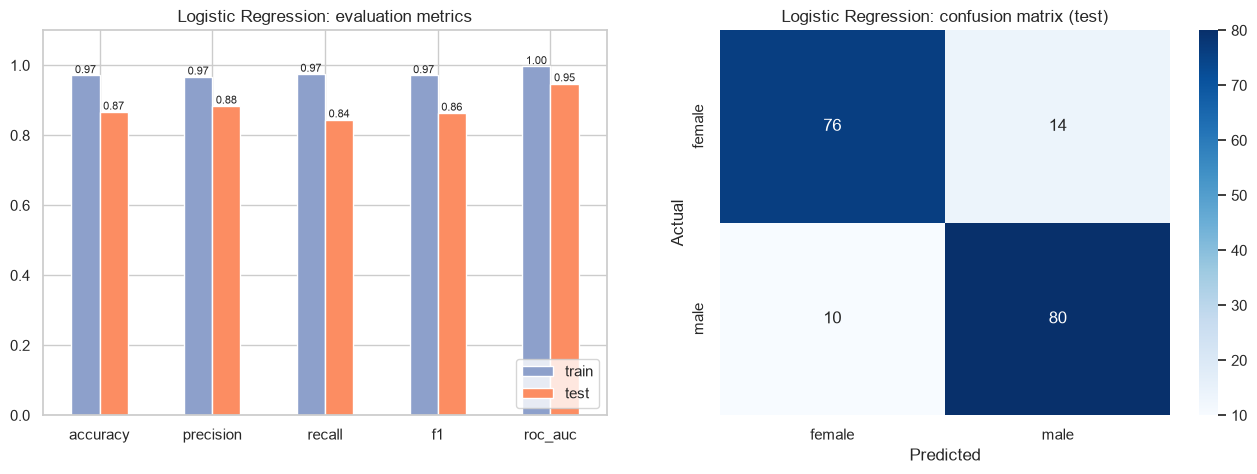

In [57]:
# Visualizing evaluation Metric Score chart
results["Logistic Regression"] = plot_scores(lr_model, "Logistic Regression")

**Model used:** Logistic Regression on TF-IDF character n-grams (1 to 4 characters). Logistic regression is a linear model that learns a weight for every n-gram and passes the weighted sum through a sigmoid to get a probability of the name being male or female. It works well on sparse text features, trains in under a second, and the weights can be read directly, which makes it easy to explain.

**Performance (default settings):**

| Metric | Train | Test |
|---|---|---|
| Accuracy | 0.971 | 0.867 |
| Precision (female) | 0.967 | 0.884 |
| Recall (female) | 0.975 | 0.844 |
| F1 | 0.971 | 0.864 |
| ROC-AUC | 0.997 | 0.948 |

The model is already good with default settings, with 86.7% test accuracy and a ROC-AUC of 0.948. The gap between train (97.1%) and test accuracy shows some overfitting, which is expected because many training names are memorised.

#### 2. Cross- Validation & Hyperparameter Tuning

Best params: {'clf__C': 10, 'tfidf__ngram_range': (1, 4), 'tfidf__sublinear_tf': False}
Best CV accuracy: 0.9069
           train   test
accuracy   0.996  0.883
precision  1.000  0.916
recall     0.992  0.844
f1         0.996  0.879
roc_auc    1.000  0.958


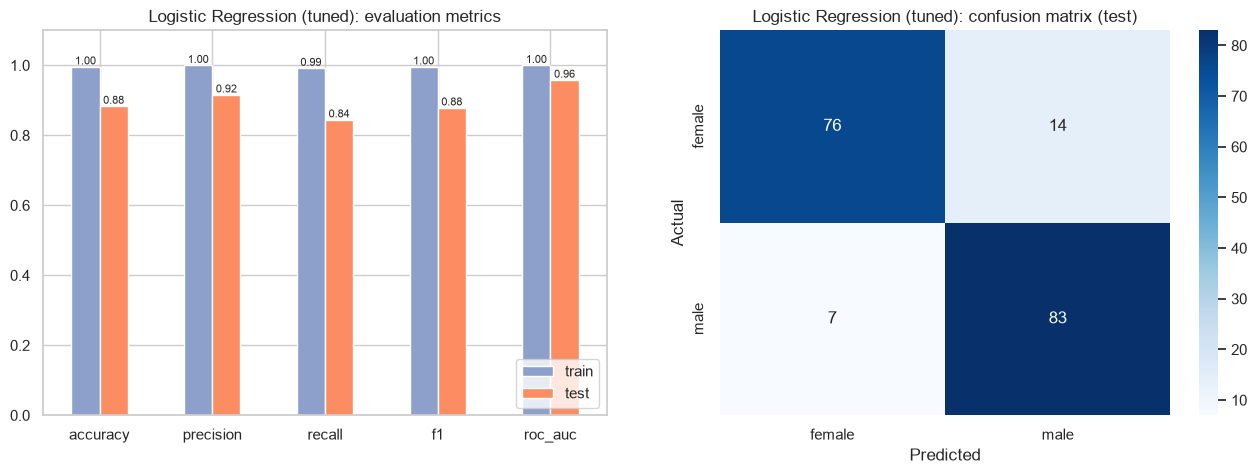

In [58]:
# ML Model - 1 Implementation with hyperparameter optimization techniques (i.e., GridSearch CV, RandomSearch CV, Bayesian Optimization etc.)
lr_grid = {
    "tfidf__ngram_range": [(1, 3), (1, 4), (2, 4), (1, 5)],
    "tfidf__sublinear_tf": [True, False],
    "clf__C": [0.5, 1, 2, 5, 10],
}
lr_search = GridSearchCV(lr_model, lr_grid, cv=cv5, scoring="accuracy", n_jobs=-1)

# Fit the Algorithm
lr_search.fit(X_train, y_train)
print("Best params:", lr_search.best_params_)
print("Best CV accuracy:", round(lr_search.best_score_, 4))
lr_tuned = lr_search.best_estimator_

# Predict on the model
y_pred_lr_tuned = lr_tuned.predict(X_test)
results["Logistic Regression (tuned)"] = plot_scores(lr_tuned, "Logistic Regression (tuned)")

##### Which hyperparameter optimization technique have you used and why?

I used GridSearchCV with 5-fold stratified cross validation. The search space is small (4 n-gram ranges x 2 sublinear_tf options x 5 values of C = 40 combinations) and each fit takes a fraction of a second, so I could try every combination instead of sampling. Grid search is the most thorough option when it is this cheap. The best parameters were C = 10, ngram_range = (1, 4) and sublinear_tf = False.

##### Have you seen any improvement? Note down the improvement with updates Evaluation metric Score Chart.

Yes. The best CV accuracy was 90.7%, and on the test set:

| Metric | Before tuning | After tuning |
|---|---|---|
| Accuracy | 0.867 | 0.883 |
| Precision | 0.884 | 0.916 |
| Recall | 0.844 | 0.844 |
| F1 | 0.864 | 0.879 |
| ROC-AUC | 0.948 | 0.958 |

Accuracy went up by 1.6 points, precision by 3.2 points and ROC-AUC from 0.948 to 0.958, while recall stayed the same. The higher C means weaker regularization, so the model trusts the strong n-grams more. On the test set it got 76 of 90 women and 83 of 90 men right.

### ML Model - 2

In [59]:
# ML Model - 2 Implementation
# Naive Bayes works on counts, so CountVectorizer instead of TF-IDF
nb_model = Pipeline([
    ("vec", CountVectorizer(analyzer="char_wb", ngram_range=(1, 4))),
    ("clf", MultinomialNB()),
])

# Fit the Algorithm
nb_model.fit(X_train, y_train)

# Predict on the model
y_pred_nb = nb_model.predict(X_test)
print("Sample predictions:", list(zip(X_test[:5], y_pred_nb[:5])))

Sample predictions: [('robin', np.str_('male')), ('lucy', np.str_('female')), ('muriel', np.str_('male')), ('alejandro', np.str_('male')), ('edna', np.str_('female'))]


#### 1. Explain the ML Model used and it's performance using Evaluation metric Score Chart.

           train   test
accuracy   0.972  0.861
precision  0.964  0.874
recall     0.980  0.844
f1         0.972  0.859
roc_auc    0.996  0.942


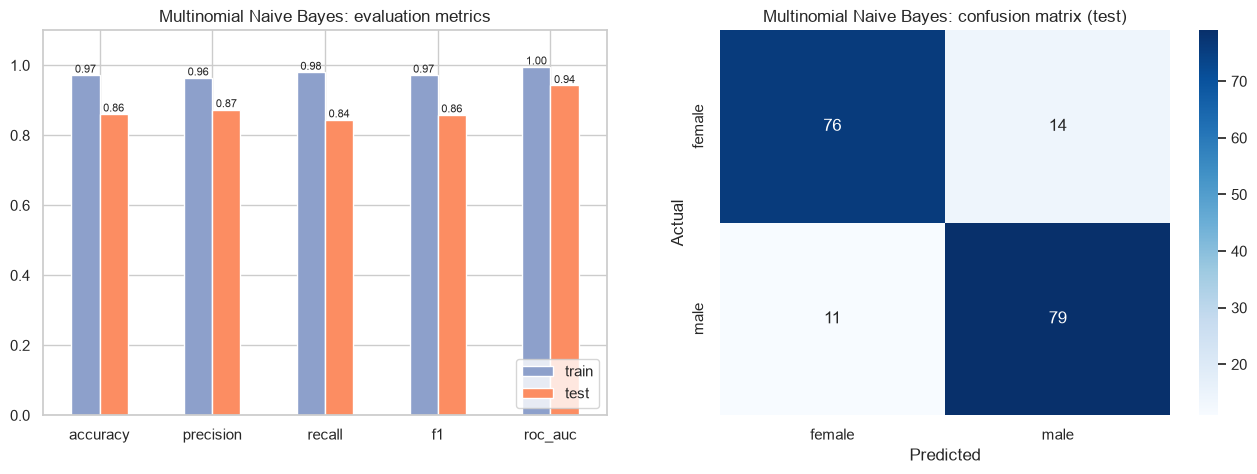

In [60]:
# Visualizing evaluation Metric Score chart
results["Naive Bayes"] = plot_scores(nb_model, "Multinomial Naive Bayes")

**Model used:** Multinomial Naive Bayes on character n-gram counts. Naive Bayes uses Bayes' theorem and assumes every n-gram is independent given the class. It learns how often each n-gram appears in female names and in male names, and picks the class with the higher probability. It is a classic, very fast baseline for text classification and works with counts, so I used CountVectorizer here instead of TF-IDF.

**Performance (default settings):**

| Metric | Train | Test |
|---|---|---|
| Accuracy | 0.972 | 0.861 |
| Precision (female) | 0.964 | 0.874 |
| Recall (female) | 0.980 | 0.844 |
| F1 | 0.972 | 0.859 |
| ROC-AUC | 0.996 | 0.942 |

With default settings Naive Bayes is slightly behind logistic regression (86.1% vs 86.7% accuracy, ROC-AUC 0.942 vs 0.948). The independence assumption is clearly not true for overlapping n-grams ("ri", "ria" and "ia" always appear together), but it still does well.

#### 2. Cross- Validation & Hyperparameter Tuning

Best params: {'clf__alpha': 0.5, 'vec__binary': True, 'vec__ngram_range': (1, 5)}
Best CV accuracy: 0.8792
           train   test
accuracy   0.982  0.883
precision  0.975  0.906
recall     0.989  0.856
f1         0.982  0.880
roc_auc    0.999  0.957


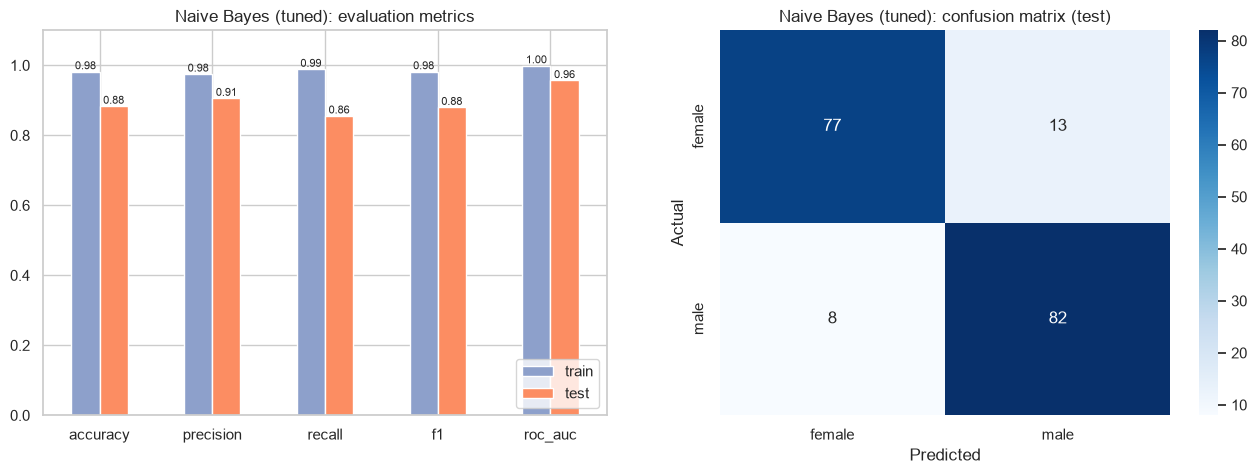

In [61]:
# ML Model - 2 Implementation with hyperparameter optimization techniques (i.e., GridSearch CV, RandomSearch CV, Bayesian Optimization etc.)
nb_grid = {
    "vec__ngram_range": [(1, 3), (1, 4), (2, 4), (1, 5)],
    "vec__binary": [True, False],
    "clf__alpha": [0.1, 0.3, 0.5, 1.0, 2.0],
}
nb_search = GridSearchCV(nb_model, nb_grid, cv=cv5, scoring="accuracy", n_jobs=-1)

# Fit the Algorithm
nb_search.fit(X_train, y_train)
print("Best params:", nb_search.best_params_)
print("Best CV accuracy:", round(nb_search.best_score_, 4))
nb_tuned = nb_search.best_estimator_

# Predict on the model
y_pred_nb_tuned = nb_tuned.predict(X_test)
results["Naive Bayes (tuned)"] = plot_scores(nb_tuned, "Naive Bayes (tuned)")

##### Which hyperparameter optimization technique have you used and why?

GridSearchCV with 5-fold stratified CV again, for the same reason as model 1: the grid is small (4 n-gram ranges x binary or counts x 5 alpha values = 40 combinations) and Naive Bayes trains almost instantly, so trying every combination was cheap. The best parameters were alpha = 0.5, binary = True and ngram_range = (1, 5).

##### Have you seen any improvement? Note down the improvement with updates Evaluation metric Score Chart.

Yes. The best CV accuracy was 87.9%, and on the test set:

| Metric | Before tuning | After tuning |
|---|---|---|
| Accuracy | 0.861 | 0.883 |
| Precision | 0.874 | 0.906 |
| Recall | 0.844 | 0.856 |
| F1 | 0.859 | 0.880 |
| ROC-AUC | 0.942 | 0.957 |

Every metric improved, accuracy by 2.2 points. Using binary counts (just whether an n-gram is present or not) helped because a short name rarely repeats the same n-gram, and longer n-grams up to 5 characters capture full endings like "ella" and "berto". The tuned Naive Bayes ties the tuned logistic regression on test accuracy (88.3%), but its CV accuracy is lower (87.9% vs 90.7%).

#### 3. Explain each evaluation metric's indication towards business and the business impact pf the ML model used.

- Accuracy is the share of users whose gender we predict correctly. Since the classes are balanced, it is a fair overall number. For the business, 88% accuracy means that out of every 100 'none' profiles we fill in, about 88 will be right.
- Precision (female) is, out of the users we label female, how many really are female. Low precision means sending female targeted campaigns to men, which wastes budget and can annoy customers.
- Recall (female) is, out of all real female users, how many we find. Low recall means female users are left out of campaigns or reports meant for them.
- F1 combines precision and recall into one number, which is useful when both kinds of mistakes matter.
- ROC-AUC measures how well the predicted probabilities rank users, whatever threshold we pick. A high AUC (0.957 here) is important because the business plan is to use only confident predictions, and that only works if the probabilities are meaningful.

Business impact: with about 88% accuracy and an AUC of 0.957, the model can fill in the missing gender for most of the 440 'none' users. Reports and segments then cover the whole customer base instead of two thirds of it, and the low confidence cases can stay unknown so we don't spread wrong labels.

### ML Model - 3

In [62]:
# ML Model - 3 Implementation
rf_model = Pipeline([
    ("tfidf", TfidfVectorizer(analyzer="char_wb", ngram_range=(1, 4))),
    ("clf", RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1)),
])

# Fit the Algorithm
rf_model.fit(X_train, y_train)

# Predict on the model
y_pred_rf = rf_model.predict(X_test)
print("Sample predictions:", list(zip(X_test[:5], y_pred_rf[:5])))

Sample predictions: [('robin', 'male'), ('lucy', 'female'), ('muriel', 'male'), ('alejandro', 'male'), ('edna', 'female')]


#### 1. Explain the ML Model used and it's performance using Evaluation metric Score Chart.

           train   test
accuracy   0.996  0.906
precision  1.000  0.962
recall     0.992  0.844
f1         0.996  0.899
roc_auc    1.000  0.963


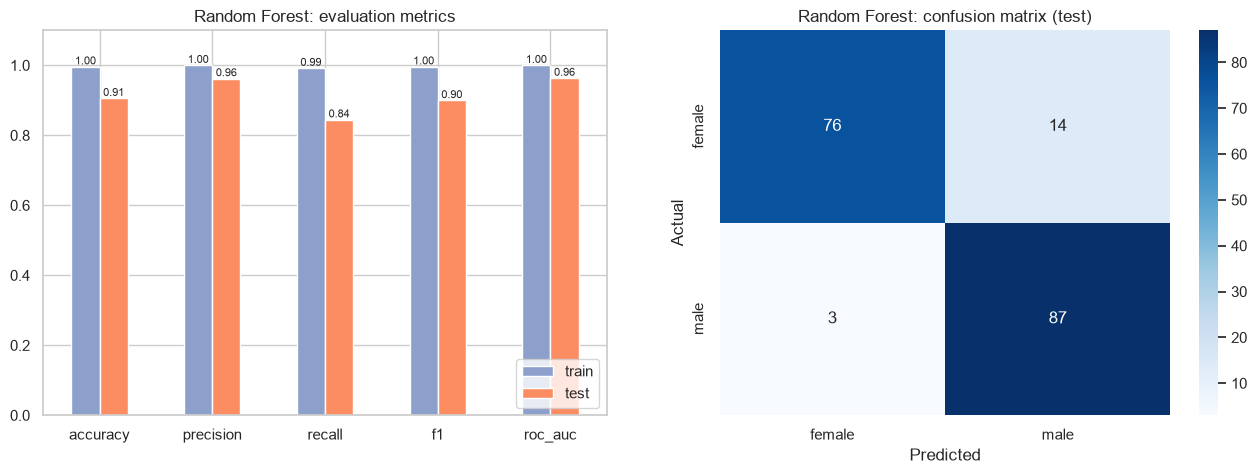

In [63]:
# Visualizing evaluation Metric Score chart
results["Random Forest"] = plot_scores(rf_model, "Random Forest")

**Model used:** Random Forest on TF-IDF character n-grams. A random forest trains many decision trees on random samples of the data and random subsets of features, and combines their votes. It can learn non-linear combinations of n-grams (for example "ends with e" but not "-ce") and is less likely to overfit than a single tree.

**Performance (default settings, 300 trees):**

| Metric | Train | Test |
|---|---|---|
| Accuracy | 0.996 | 0.906 |
| Precision (female) | 1.000 | 0.962 |
| Recall (female) | 0.992 | 0.844 |
| F1 | 0.996 | 0.899 |
| ROC-AUC | 1.000 | 0.963 |

Random forest gets the highest test accuracy of the default models (90.6%) and very high precision (0.962). But it fits the training data almost perfectly (99.6%), so it memorises names heavily. The test set has only 180 names, so the 2.3 point gap over logistic regression is just 4 names, and I don't want to read too much into one split.

#### 2. Cross- Validation & Hyperparameter Tuning

Best params: {'tfidf__ngram_range': (2, 4), 'clf__n_estimators': 500, 'clf__min_samples_leaf': 1, 'clf__max_features': 'sqrt', 'clf__max_depth': 40}
Best CV accuracy: 0.9014
           train   test
accuracy   0.992  0.889
precision  1.000  0.938
recall     0.983  0.833
f1         0.992  0.882
roc_auc    1.000  0.958


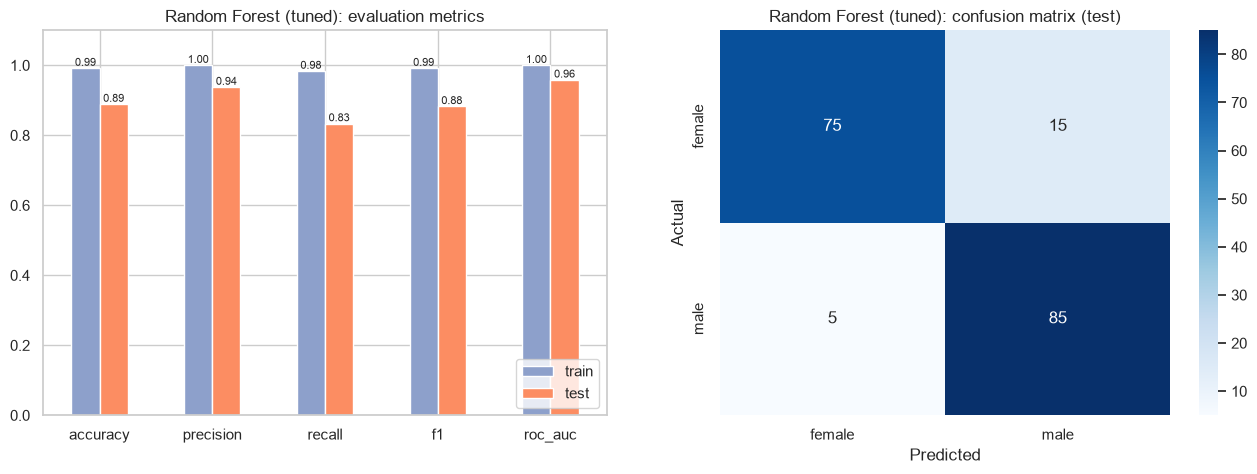

In [64]:
# ML Model - 3 Implementation with hyperparameter optimization techniques (i.e., GridSearch CV, RandomSearch CV, Bayesian Optimization etc.)
rf_dist = {
    "tfidf__ngram_range": [(1, 3), (1, 4), (2, 4)],
    "clf__n_estimators": [200, 300, 500],
    "clf__max_depth": [None, 20, 40],
    "clf__min_samples_leaf": [1, 2, 3],
    "clf__max_features": ["sqrt", "log2", 0.05],
}
rf_search = RandomizedSearchCV(rf_model.set_params(clf__n_jobs=1), rf_dist, n_iter=20, cv=cv5,
                               scoring="accuracy", n_jobs=-1, random_state=RANDOM_STATE)

# Fit the Algorithm
rf_search.fit(X_train, y_train)
print("Best params:", rf_search.best_params_)
print("Best CV accuracy:", round(rf_search.best_score_, 4))
rf_tuned = rf_search.best_estimator_

# Predict on the model
y_pred_rf_tuned = rf_tuned.predict(X_test)
results["Random Forest (tuned)"] = plot_scores(rf_tuned, "Random Forest (tuned)")

##### Which hyperparameter optimization technique have you used and why?

I used RandomizedSearchCV with 5-fold stratified CV and 20 random combinations. The random forest has more hyperparameters (n-gram range, number of trees, max depth, min samples per leaf, max features), and the full grid would be 3 x 3 x 3 x 3 x 3 = 243 combinations of a much slower model. Randomized search covers the space well with far fewer fits. The best parameters were 500 trees, max_depth = 40, min_samples_leaf = 1, max_features = "sqrt" and ngram_range = (2, 4).

##### Have you seen any improvement? Note down the improvement with updates Evaluation metric Score Chart.

In cross validation, yes: the best CV accuracy was 90.1%. On the test set it actually went down a little:

| Metric | Before tuning | After tuning |
|---|---|---|
| Accuracy | 0.906 | 0.889 |
| Precision | 0.962 | 0.938 |
| Recall | 0.844 | 0.833 |
| F1 | 0.899 | 0.882 |
| ROC-AUC | 0.963 | 0.958 |

The tuned model is 3 names worse on the 180-name test set. The search picks the setting that is best on average over 5 folds of 720 training names, which is a more reliable estimate than one small test split. So I see this as normal noise and not as tuning making the model worse. It does show that random forest doesn't gain much from tuning on this data.

                             accuracy  precision  recall     f1  roc_auc
Logistic Regression             0.867      0.884   0.844  0.864    0.948
Logistic Regression (tuned)     0.883      0.916   0.844  0.879    0.958
Naive Bayes                     0.861      0.874   0.844  0.859    0.942
Naive Bayes (tuned)             0.883      0.906   0.856  0.880    0.957
Random Forest                   0.906      0.962   0.844  0.899    0.963
Random Forest (tuned)           0.889      0.938   0.833  0.882    0.958


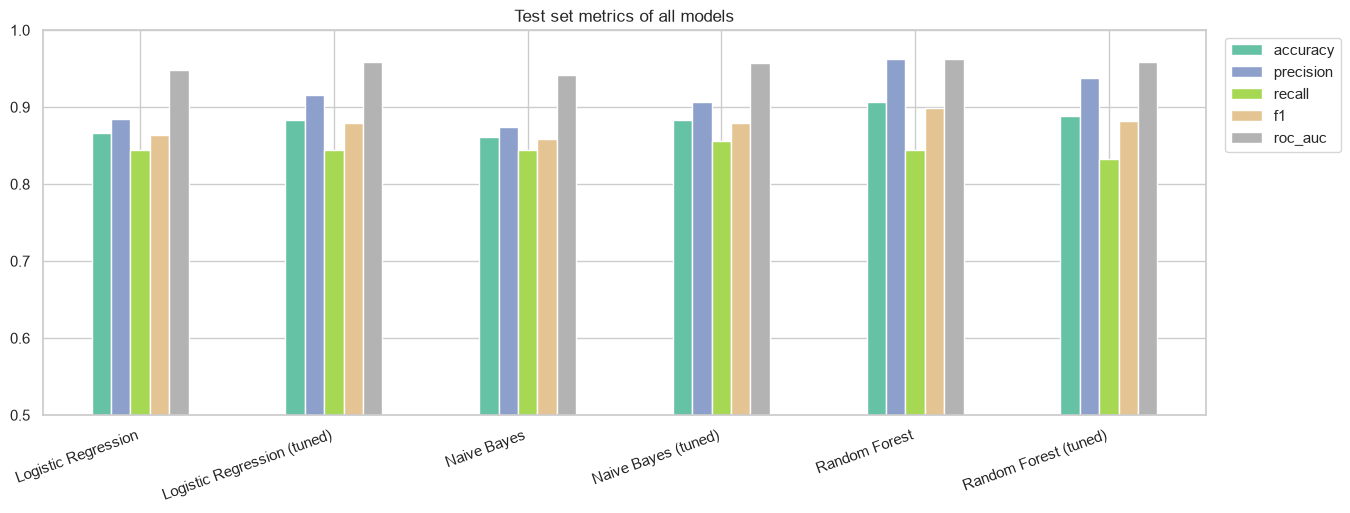

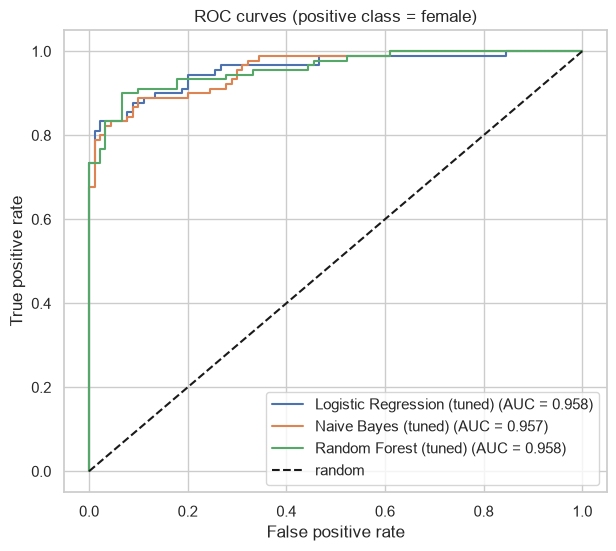

In [65]:
# all six models side by side on the test set
comparison = pd.DataFrame(results).T.round(3)
print(comparison)

comparison.plot(kind="bar", figsize=(15, 5), colormap="Set2")
plt.title("Test set metrics of all models")
plt.ylim(0.5, 1.0)
plt.xticks(rotation=20, ha="right")
plt.legend(bbox_to_anchor=(1.01, 1))
plt.show()

# ROC curves of the tuned models
plt.figure(figsize=(7, 6))
for name, model in [("Logistic Regression (tuned)", lr_tuned), ("Naive Bayes (tuned)", nb_tuned),
                    ("Random Forest (tuned)", rf_tuned)]:
    proba = model.predict_proba(X_test)[:, list(model.classes_).index(POS_LABEL)]
    fpr, tpr, _ = roc_curve((y_test == POS_LABEL).astype(int), proba)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {roc_auc_score((y_test == POS_LABEL).astype(int), proba):.3f})")
plt.plot([0, 1], [0, 1], "k--", label="random")
plt.xlabel("False positive rate")
plt.ylabel("True positive rate")
plt.title("ROC curves (positive class = female)")
plt.legend()
plt.show()

### 1. Which Evaluation metrics did you consider for a positive business impact and why?

I mainly looked at accuracy and ROC-AUC, and also checked precision for the female class.

- Accuracy, because the two classes are balanced and the business cares equally about labeling men and women correctly.
- ROC-AUC, because the plan is to fill in only the confident predictions. That needs good probabilities, and AUC measures exactly that.
- Precision, because a wrong label is worse than no label. Sending someone a campaign for the wrong gender is a bad customer experience, while an unknown profile just stays as it is today.

I also used CV accuracy and accuracy on unseen names (GroupKFold) to make the final choice, because the 180-name test set is small and 61% of its names are already in the training data.

### 2. Which ML model did you choose from the above created models as your final prediction model and why?

In [66]:
# Harder test: names the model has NEVER seen. GroupKFold keeps every copy of a first name in the same fold,
# so the score shows how well each model generalises to new names instead of remembering known ones.
group_cv = GroupKFold(n_splits=5)
unseen = {}
for name, model in [("Logistic Regression (tuned)", lr_tuned), ("Naive Bayes (tuned)", nb_tuned),
                    ("Random Forest (tuned)", rf_tuned)]:
    scores = cross_val_score(model, X, y, groups=X, cv=group_cv, scoring="accuracy")
    unseen[name] = round(scores.mean(), 3)
print("Accuracy on unseen first names (GroupKFold by name):")
print(pd.Series(unseen))

Accuracy on unseen first names (GroupKFold by name):
Logistic Regression (tuned)    0.756
Naive Bayes (tuned)            0.722
Random Forest (tuned)          0.719
dtype: float64


I chose the **tuned Logistic Regression** as the final model.

Looking only at the test table, all tuned models are close (88.3% to 88.9% accuracy) and the untuned random forest was best at 90.6%. But a 180-name test set is too small to decide on, because one or two names change the ranking. So I used two more reliable checks:

1. 5-fold CV accuracy on the training set: logistic regression 90.7%, random forest 90.1%, Naive Bayes 87.9%.
2. Accuracy on first names never seen in training (GroupKFold by name, the cell above): logistic regression 75.6%, Naive Bayes 72.2%, random forest 71.9%.

Logistic regression is the best on both. The second check matters a lot, because new users will often have names that are not in our data, and that is exactly where random forest drops the most. On top of that, logistic regression gives smooth probabilities for the confidence threshold, it is the easiest to explain, it predicts in microseconds, and the saved file is only 70 KB, which makes it a good fit for an API or the Streamlit app.

### 3. Explain the model which you have used and the feature importance using any model explainability tool?

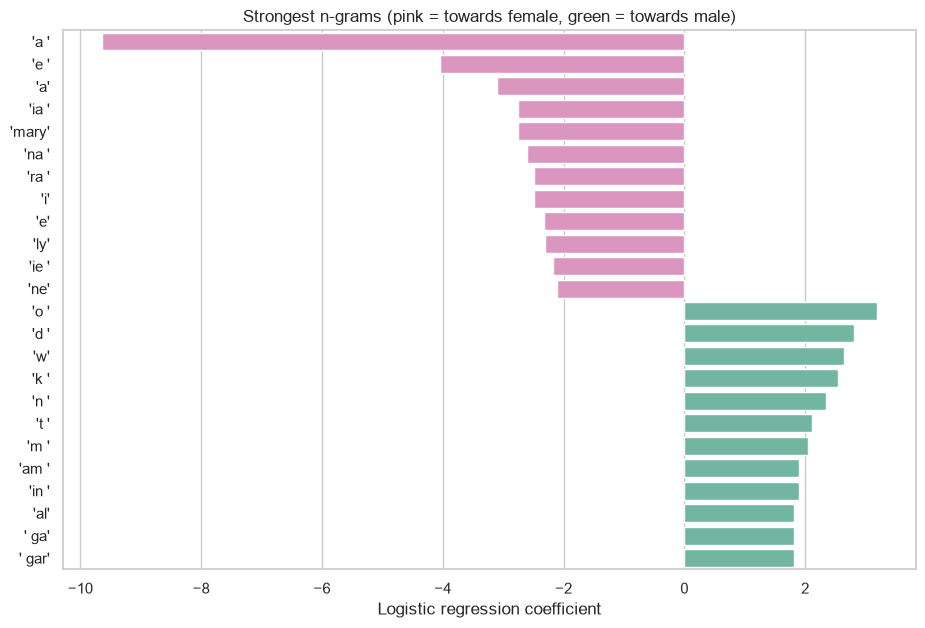

In [67]:
# 1) global view: n-grams with the largest logistic regression coefficients
# classes_ = ['female', 'male'], so a positive coefficient pushes towards male and a negative one towards female
vec = lr_tuned.named_steps["tfidf"]
clf = lr_tuned.named_steps["clf"]
coefs = pd.Series(clf.coef_[0], index=vec.get_feature_names_out())
top = pd.concat([coefs.nsmallest(12), coefs.nlargest(12)])

plt.figure(figsize=(11, 7))
sns.barplot(x=top.values, y=[repr(i) for i in top.index], palette=["#e78ac3"] * 12 + ["#66c2a5"] * 12)
plt.title("Strongest n-grams (pink = towards female, green = towards male)")
plt.xlabel("Logistic regression coefficient")
plt.show()

edna       -> predicted female (P(female) = 0.98)


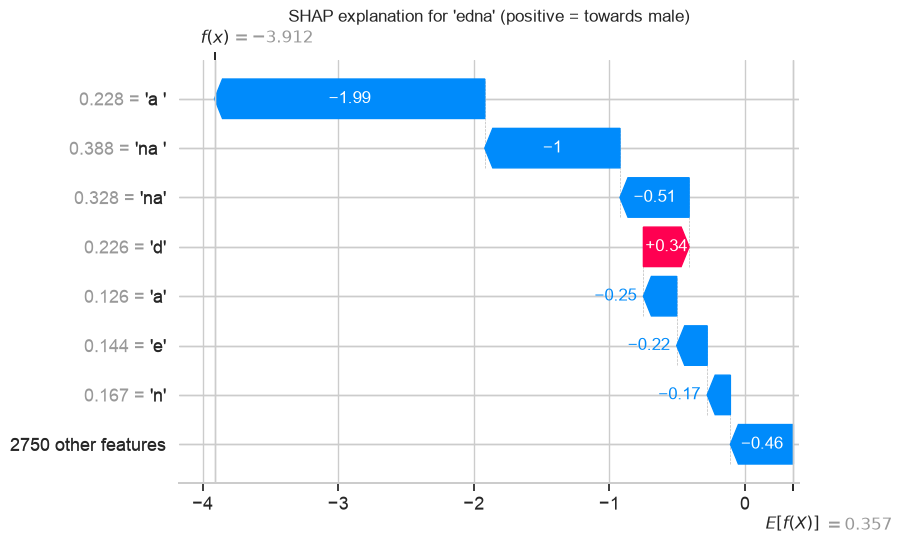

alejandro  -> predicted male   (P(female) = 0.21)


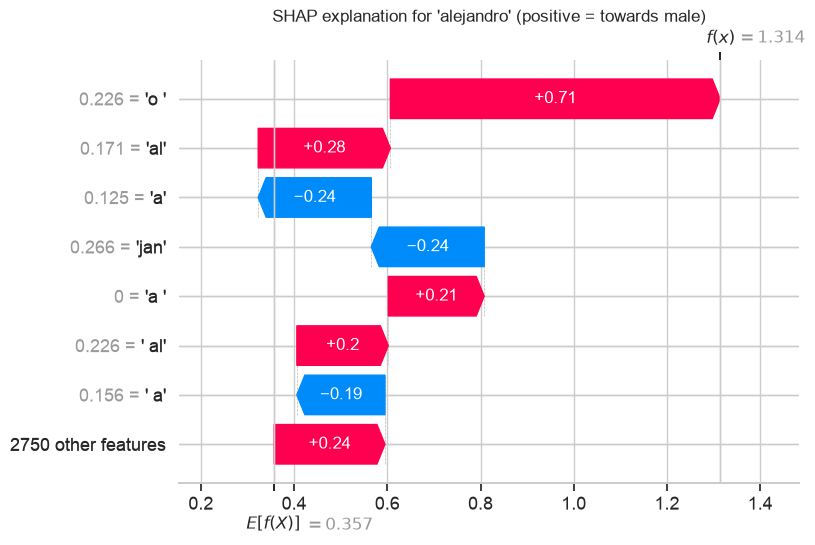

lucy       -> predicted female (P(female) = 0.51)


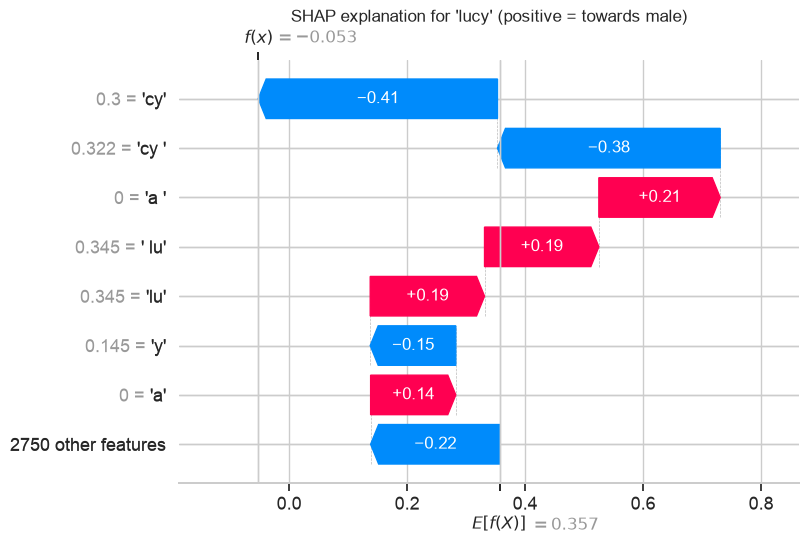

robin      -> predicted male   (P(female) = 0.10)


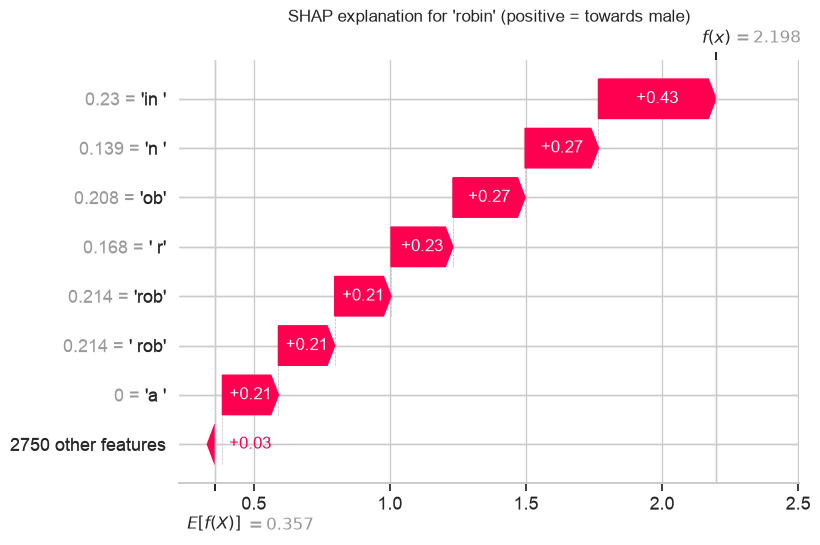

In [68]:
# 2) local view with SHAP: why the model gave a certain answer for single names
import logging
logging.getLogger("shap").setLevel(logging.ERROR)   # hides the info message about background sampling

X_train_vec = vec.transform(X_train)
explainer = shap.LinearExplainer(clf, X_train_vec)
sample_names = pd.Series(["edna", "alejandro", "lucy", "robin"])
shap_values = explainer(vec.transform(sample_names))
# quotes around the n-grams so the word boundary space is visible ('a ' = name ends with a)
shap_values.feature_names = [repr(f) for f in vec.get_feature_names_out()]

for i, nm in enumerate(sample_names):
    proba = lr_tuned.predict_proba([nm])[0]
    print(f"{nm:<10} -> predicted {lr_tuned.predict([nm])[0]:<6} (P(female) = {proba[0]:.2f})")
    shap.plots.waterfall(shap_values[i], max_display=8, show=False)
    plt.title(f"SHAP explanation for '{nm}' (positive = towards male)")
    plt.show()

The final model is a pipeline of TF-IDF character n-grams (1 to 4 characters) and logistic regression with C = 10. Every n-gram gets one weight. Since the classes are ordered ['female', 'male'], a positive weight pushes the prediction towards male and a negative weight towards female. The predicted probability is the sigmoid of the sum of weight x TF-IDF value over all n-grams in the name.

Global feature importance (coefficient chart): the strongest feature by far is "a " (the name ends in a) with a weight of about -9.6, then "e ", "ia ", "na ", "ra " and "ie ", all pointing to female. On the male side the top features are "o " (ends in o), "d ", "k ", "n ", "t ", "m " and pieces like "al" and " gar". This matches chart 8 and the chi-square results, so the model learned the real pattern and not something random.

Local explanations with SHAP: I used shap.LinearExplainer, which works out exactly how much each n-gram added to the prediction for one name compared to an average name.

- edna is predicted female with P(female) = 0.98. SHAP shows "a " pulls it strongly to female (about -2 on the log-odds scale), helped by "na " and "na". The "d" pushes a little towards male but can't outweigh the ending.
- alejandro is predicted male (P(female) = 0.21), mostly because of "o ".
- lucy sits right on the line with P(female) = 0.51. Names ending in "y" are 50/50 in this data, so the model is unsure, which is the honest answer.
- robin is predicted male (P(female) = 0.10), but robin is one of the 6 names used by both genders in our data. This is the kind of mistake no model can fully avoid, and it's why I return a confidence with every prediction.

## ***8.*** ***Future Work (Optional)***

### 1. Save the best performing ml model in a pickle file or joblib file format for deployment process.


In [69]:
# Save the File
final_model = lr_tuned
bundle = {
    "pipeline": final_model,                       # input: list/Series of lowercased first names
    "classes": list(final_model.classes_),
    "model_name": "logistic_regression",
    "metrics": {k: float(v) for k, v in results["Logistic Regression (tuned)"].items()},
    "trained_at": pd.Timestamp.now(tz="UTC").isoformat(timespec="seconds"),
}
MODEL_DIR = "../models" if os.path.isdir("../models") else "."
MODEL_PATH = os.path.join(MODEL_DIR, "gender_model.joblib")
joblib.dump(bundle, MODEL_PATH)
print("Model saved to", MODEL_PATH, "| size:", round(os.path.getsize(MODEL_PATH) / 1024, 1), "KB")

Model saved to ../models/gender_model.joblib | size: 70.0 KB


### 2. Again Load the saved model file and try to predict unseen data for a sanity check.


In [70]:
# Load the File and predict unseen data.
loaded = joblib.load(MODEL_PATH)
model = loaded["pipeline"]
print("Loaded:", loaded["model_name"], "| trained at:", loaded["trained_at"])

# names that are not in the dataset at all
new_people = ["Maria Souza", "Joao Pereira", "Emily Clark", "Robert King", "Ana Lima", "Lucas Martins"]
first_names = [to_first_name(n) for n in new_people]
proba = model.predict_proba(first_names)
pd.DataFrame({"name": new_people, "first_name": first_names, "predicted": model.predict(first_names),
              "P(female)": proba[:, 0].round(3), "P(male)": proba[:, 1].round(3)})

Loaded: logistic_regression | trained at: 2026-10-26T08:39:21+00:00


,name,first_name,predicted,P(female),P(male)
0,Maria Souza,maria,female,0.992,0.008
1,Joao Pereira,joao,male,0.272,0.728
2,Emily Clark,emily,female,0.771,0.229
3,Robert King,robert,male,0.014,0.986
4,Ana Lima,ana,female,0.981,0.019
5,Lucas Martins,lucas,male,0.189,0.811


In [71]:
# the 'none' users from the dataset: the model fills in the missing gender with a confidence score
none_proba = model.predict_proba(unlabeled["first_name_clean"])
none_pred = pd.DataFrame({"name": unlabeled["name"], "predicted": model.predict(unlabeled["first_name_clean"]),
                          "confidence": none_proba.max(axis=1).round(3)})
print("Predicted gender for the", len(none_pred), "'none' users:")
print(none_pred["predicted"].value_counts().to_string())
print(f"Predictions with confidence >= 0.8: {(none_pred['confidence'] >= 0.8).mean():.1%}")
none_pred.head(10)

Predicted gender for the 440 'none' users:
predicted
female    222
male      218
Predictions with confidence >= 0.8: 78.4%


,name,predicted,confidence
0,Trina Thomas,female,0.961
1,Jack Sabo,male,0.874
2,Debbie Helms,female,0.929
3,Irene Tucker,female,0.950
4,Victor Tribbett,male,0.868
5,Tanya Orourke,female,0.879
6,Christopher Elliott,male,0.952
7,Helen Selby,female,0.926
8,Anna Rodriguez,female,0.993
9,Denise Newton,female,0.733


### ***Congrats! Your model is successfully created and ready for deployment on a live server for a real user interaction !!!***

# **Conclusion**

- In this dataset, gender cannot be predicted from age, company or travel behaviour. Charts, hypothesis tests (t-test p = 0.58, chi-square p = 0.79) and cross validation (47% to 49% accuracy) all showed no relationship. The only useful information is in the first name.
- The 'none' value is missing data, not a third gender. Most of those users have ordinary male or female first names, so I trained on male vs female and used the model to fill in the 'none' users.
- TF-IDF character n-grams work much better than whole names because they pick up endings like "-a", "-ia", "-d" and "-o", which also works for names the model has never seen.
- The final model is a tuned Logistic Regression with 90.7% CV accuracy and, on the test set, 88.3% accuracy, 0.916 precision, 0.844 recall and 0.958 ROC-AUC. On completely unseen names it gets 75.6%, which is a more realistic number for brand new users.
- When filling in the 440 'none' users, it predicts 222 female and 218 male, and 78.4% of those predictions have a confidence of 0.8 or more. The business should only use predictions above a threshold like 0.8 and keep the rest as unknown.
- Limitations: a name based model will always struggle with unisex names (6 in this data, like robin and kim), and it assumes names follow mostly English naming patterns. Predictions should only be used for aggregate reports and segments, never for decisions about a single person. The best long term fix is still to collect gender properly at sign up, with an option not to say.
- The model is saved as a small joblib file (70 KB) together with its metrics, so it can be loaded by the training script, the API and the Streamlit app in the rest of the project.

### ***Hurrah! You have successfully completed your Machine Learning Capstone Project !!!***